# Assignment --- Prompt-Guided Animal Body-Part Segmentation and Description



This notebook builds **two complete systems** that take an animal photo and a natural-language prompt
(*"Show the wings of this bird"*), segment the requested body part, show the isolated part, and write a short
description of its appearance and biological function. It then compares them **on the same images and prompts**.

| | **System A** (no VLM) | **System B** (VLM) |
|---|---|---|
| Understand the prompt | rule-based parser (synonym dictionary) | Qwen2.5-VL-3B reads the request (JSON) |
| Find the animal / part | YOLOv8x finds the animal, **spatial priors learned from Pascal-Part** place the part | Qwen2.5-VL **grounds** the part (bounding boxes) |
| Segment | SAM 2.1 (box prompt) | SAM 2.1 (box prompt) |
| Describe | predefined knowledge base (optionally a *text-only* LLM) | Qwen2.5-VL describes the isolated region **in context** |

| Assignment task | Where it is done |
|---|---|
| **A1–A2** conventional CV + DL system (YOLO, SAM 2) that segments parts from text | §2 (data and priors), §3 (components), §4 (System A) |
| **A3** description from predefined text / text-only LM | §3.1 (knowledge base), §4 |
| **A4 / B** interactive UI showing the isolated part and its description | §6 |
| **B1–B4** VLM + localisation + segmentation + context-aware description | §5 (System B), §6 |
| **C1** same images and prompts for both systems | §2.4 (evaluation set), §7 |
| **C2** segmentation, prompt following, descriptions, compute | §8 |
| **C3** IoU and Dice against ground-truth masks | §7.1, §8.1–8.3 |
| **C4** advantages, limitations, suitability | §8.9, §9, §10 |
| Deliverables: code, samples, outputs, comparative results, report | §2.5, §8, §10.3 (exports for the LaTeX report) |

### Design in one paragraph

Promptable segmenters such as SAM 2 draw excellent masks **if they are given a good prompt**, but they do not
understand text. The whole problem therefore reduces to *where does the box come from?* In **System A** it comes
from engineered knowledge: a detector finds the animal, and the median position of each part inside the animal
box, learned from training annotations, supplies the part box. In **System B** it comes from a vision-language
model that looks at the picture and returns the box itself. Both systems use **the same SAM 2 weights**, so any
difference in the masks is caused by the prompting stage alone.

> **Important facts about the evaluation.**
> 1. Ground truth comes from **Pascal-Part** (Chen *et al.*, CVPR 2014): pixel masks of body parts for six VOC
>    animals (cat, dog, bird, horse, cow, sheep). The annotated images are split **70 / 30 by image**: the 70 % is
>    used *only* to learn System A's priors; **evaluation uses the unseen 30 %**, so no prior was fitted on an
>    evaluated image.
> 2. Every evaluation image contains **exactly one** animal of its class, so "which cat?" is never ambiguous.
> 3. Pascal-Part's masks are partly coarse (hand-drawn polygons), so even a perfect segmenter would not reach
>    IoU = 1. §9 measures this ceiling by prompting SAM 2 with the *ground-truth* box.

## 0. Environment

Designed for **Google Colab with a GPU** (a free T4 is enough; all three large models fit in 15 GB in half precision).
Run the next cell once. Nothing needs to be restarted afterwards.

In [1]:
%pip install -q ultralytics gradio "transformers>=4.49" accelerate qwen-vl-utils sentence-transformers scipy pandas matplotlib opencv-python-headless tabulate
%pip install -q git+https://github.com/facebookresearch/sam2.git

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 34.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 3.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 12.2 MB/s eta 0:00:00


---
# 1. Imports, configuration and reproducibility

All settings live in one `Config` object. Increase `n_per_class` for the final numbers (12 per class gives about
144 prompts and takes roughly 15 minutes on a T4, almost all of it in System B's three VLM generations per prompt).

In [2]:
import os, sys, re, json, time, gc, math, random, pickle, glob, shutil, subprocess, warnings, itertools
from pathlib import Path
from dataclasses import dataclass, asdict, field
from collections import defaultdict

import numpy as np
import pandas as pd
import torch
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

# ----------------------------------------------------------------- paths
ROOT = Path("/content/animal_parts") if Path("/content").exists() else Path.cwd() / "animal_parts"
DATA = ROOT / "data"
OUT  = ROOT / "outputs"
FIG, RES, SAMPLES, CUTS, MASKS = OUT / "figures", OUT / "results", OUT / "samples", OUT / "cutouts", OUT / "masks"
REPORT = OUT / "report_assets" / "results"          # files read by report.tex
for d in (DATA, FIG, RES, SAMPLES, CUTS, MASKS, REPORT):
    d.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------------- config
@dataclass
class Config:
    classes: tuple        = ("cat", "dog", "bird", "horse", "cow", "sheep")
    # ---- evaluation set
    n_per_class: int      = 12        # images per species
    parts_per_image: int  = 2         # prompts (parts) per image
    min_obj_frac: float   = 0.08      # animal must cover >= 8 % of the image
    min_part_frac: float  = 0.003     # part must cover >= 0.3 % of the image
    train_frac: float     = 0.70      # image-level split: priors vs. evaluation
    # ---- System A
    n_prior_files: int    = 3000      # training annotation files scanned for priors
    min_prior_count: int  = 15        # minimum examples to trust a (species, part) prior
    yolo_weights: str     = "yolov8x.pt"
    yolo_conf: float      = 0.25
    sam_cand_penalty: float = 0.3     # weight of the "mask much larger than box" penalty
    # ---- System B
    vlm_id: str           = "Qwen/Qwen2.5-VL-3B-Instruct"
    vlm_max_pixels: int   = 1024 * 28 * 28
    # ---- shared
    sam_id: str           = "facebook/sam2.1-hiera-large"
    seed: int             = 0

CFG = Config()
assert torch.cuda.is_available(), "Please select a GPU runtime (Runtime > Change runtime type)."
DEV = torch.device("cuda")
AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(CFG.seed)

print("torch", torch.__version__, "| device:", torch.cuda.get_device_name(0), "| half precision:", str(AMP_DTYPE).split(".")[-1])
print(json.dumps({k: (list(v) if isinstance(v, tuple) else v) for k, v in asdict(CFG).items()}, indent=1))

torch 2.11.0+cu130 | device: Tesla T4 | half precision: bfloat16
{
 "classes": [
  "cat",
  "dog",
  "bird",
  "horse",
  "cow",
  "sheep"
 ],
 "n_per_class": 12,
 "parts_per_image": 2,
 "min_obj_frac": 0.08,
 "min_part_frac": 0.003,
 "train_frac": 0.7,
 "n_prior_files": 3000,
 "min_prior_count": 15,
 "yolo_weights": "yolov8x.pt",
 "yolo_conf": 0.25,
 "sam_cand_penalty": 0.3,
 "vlm_id": "Qwen/Qwen2.5-VL-3B-Instruct",
 "vlm_max_pixels": 802816,
 "sam_id": "facebook/sam2.1-hiera-large",
 "seed": 0
}


In [3]:
# ---------------------------------------------------------------- plotting style
# Fixed colour per system so a system looks the same in every figure.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, INK3 = "#0b0b0b", "#52514e", "#8a8984"
SURFACE, GRIDC = "#ffffff", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRIDC, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 160,
    "savefig.bbox": "tight", "lines.linewidth": 1.8, "figure.max_open_warning": 0,
})
SEQ_BLUE = LinearSegmentedColormap.from_list("seqblue", ["#ffffff", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#eb6834", "#ffffff", "#2a78d6"])      # blue = System B better
A_, B_ = "A_noVLM", "B_VLM"
SYS_NAMES = {A_: "A (no VLM)", B_: "B (VLM)", "Oracle": "SAM 2 + GT box"}
SYS_COLOR = {A_: PALETTE[0], B_: PALETTE[1], "Oracle": PALETTE[2]}

def savefig(fig, name):
    fig.savefig(FIG / name); print("saved ->", (FIG / name).relative_to(ROOT))

# ---------------------------------------------------------------- mask / box helpers
def mask_bbox(m):
    ys = np.where(m.any(1))[0]; xs = np.where(m.any(0))[0]
    if len(ys) == 0: return None
    return int(xs[0]), int(ys[0]), int(xs[-1]) + 1, int(ys[-1]) + 1

def iou_dice(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool)
    inter = (pred & gt).sum(); union = (pred | gt).sum()
    iou = inter / union if union else 0.0
    dice = 2 * inter / (pred.sum() + gt.sum()) if (pred.sum() + gt.sum()) else 0.0
    return float(iou), float(dice)

def box_iou(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0

def overlay(pil, mask, boxes=(), color=(255, 0, 0), alpha=0.5, box_color=(0, 255, 0)):
    arr = np.array(pil.convert("RGB")).copy()
    if mask is not None and mask.any():
        arr[mask] = (arr[mask] * (1 - alpha) + np.array(color) * alpha).astype(np.uint8)
        cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(arr, cnts, -1, (255, 255, 0), 2)
    for b in boxes:
        cv2.rectangle(arr, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), box_color, 2)
    return Image.fromarray(arr)

def make_cutout(pil, mask, margin=6):
    # the isolated body part: RGBA, transparent outside the mask, cropped to the part
    bb = mask_bbox(mask)
    if bb is None: return None
    H, W = mask.shape
    x1, y1, x2, y2 = max(0, bb[0] - margin), max(0, bb[1] - margin), min(W, bb[2] + margin), min(H, bb[3] + margin)
    rgba = np.dstack([np.array(pil.convert("RGB")), (mask * 255).astype(np.uint8)])
    return Image.fromarray(rgba[y1:y2, x1:x2], "RGBA")

def count_params(m): return sum(p.numel() for p in m.parameters()) / 1e6

def boot_ci(x, n=2000, seed=0):
    # 95 % bootstrap confidence interval of the mean
    x = np.asarray(x, float); rng = np.random.default_rng(seed)
    means = rng.choice(x, (n, len(x))).mean(1)
    return tuple(np.percentile(means, [2.5, 97.5]))

def heatmap(ax, M, rlabels, clabels, title, fmt="{:.2f}", vmin=None, vmax=None, cmap=SEQ_BLUE):
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(clabels))); ax.set_xticklabels(clabels, rotation=45, ha="right")
    ax.set_yticks(range(len(rlabels))); ax.set_yticklabels(rlabels); ax.grid(False)
    lo, hi = np.nanmin(M), np.nanmax(M)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M[i, j]
            if np.isfinite(v):
                dark = (v - lo) / (hi - lo + 1e-9) > 0.6 if cmap is SEQ_BLUE else abs(v) > 0.6 * max(abs(lo), abs(hi))
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=7, color="white" if dark else INK)
    ax.set_title(title); return im

def grouped_bar(ax, table, title, rot=0, ylim=(0, 1)):
    x = np.arange(len(table.index)); cols = [c for c in (A_, B_) if c in table.columns]; w = 0.8 / len(cols)
    for k, c in enumerate(cols):
        ax.bar(x + (k - (len(cols) - 1) / 2) * w, table[c].values, w, color=SYS_COLOR[c], label=SYS_NAMES[c])
    ax.set_xticks(x); ax.set_xticklabels(table.index, rotation=rot, ha="right" if rot else "center")
    if ylim: ax.set_ylim(*ylim)
    ax.set_title(title); ax.legend()

---
# 2. Data: Pascal-Part ground truth, split, priors and the evaluation set

## 2.1 Downloading the data

* **Pascal-Part annotations** (Chen *et al.*, 2014): for every VOC2010 trainval image, a `.mat` file with the
  object masks and the **part masks** (head, ear, eye, leg, wing, tail, ...).
* **PASCAL VOC 2010 images** (Everingham *et al.*, 2010), about 1.3 GB.

Both are downloaded automatically. If a host is unreachable, put your own copy on Google Drive and set
`PP_LOCAL` / `VOC_LOCAL` to the archive path. If neither source works at all, the notebook falls back to
**Oxford-IIIT Pet** with *head boxes* as a (coarse) ground truth, so the pipeline still runs end to end.

In [4]:
PP_URLS = ["http://roozbehm.info/pascal-parts/trainval.tar.gz",
           "https://www.cs.stanford.edu/~roozbeh/pascal-parts/trainval.tar.gz"]
VOC_URL = "http://host.robots.ox.ac.uk/pascal/VOC/voc2010/VOCtrainval_03-May-2010.tar"
PP_LOCAL, VOC_LOCAL = "", ""            # optional: path to your own copies (e.g. on Google Drive)

def wget(url, dst):
    dst = Path(dst)
    if dst.exists() and dst.stat().st_size > 1e6: return True
    r = subprocess.run(["wget", "-q", "--tries=2", "--timeout=60", "-O", str(dst), url])
    ok = r.returncode == 0 and dst.exists() and dst.stat().st_size > 1e6
    if not ok and dst.exists(): dst.unlink()
    return ok

PP_DIR, VOC_DIR = DATA / "pascal_part", DATA / "voc"
PP_DIR.mkdir(exist_ok=True); VOC_DIR.mkdir(exist_ok=True)
if not list(PP_DIR.rglob("*.mat")):
    tar = Path(PP_LOCAL) if PP_LOCAL else DATA / "pascal_part.tar.gz"
    if tar.exists() or any(wget(u, tar) for u in PP_URLS):
        subprocess.run(["tar", "-xzf", str(tar), "-C", str(PP_DIR)])
if not list(VOC_DIR.rglob("JPEGImages/*.jpg")):
    tar = Path(VOC_LOCAL) if VOC_LOCAL else DATA / "voc2010.tar"
    if tar.exists() or wget(VOC_URL, tar):
        subprocess.run(["tar", "-xf", str(tar), "-C", str(VOC_DIR), "--wildcards", "*JPEGImages/*"])

ANN_FILES = sorted(str(p) for p in PP_DIR.rglob("*.mat"))
VOC_IMG = {p.stem: str(p) for p in VOC_DIR.rglob("JPEGImages/*.jpg")}
USE_PASCAL = len(ANN_FILES) > 100 and len(VOC_IMG) > 100
print(f"Pascal-Part annotation files: {len(ANN_FILES)} | VOC images: {len(VOC_IMG)} | use Pascal-Part: {USE_PASCAL}")

Pascal-Part annotation files: 10103 | VOC images: 11321 | use Pascal-Part: True


## 2.2 Reading the annotations and defining the part vocabulary

Pascal-Part names every sub-part separately (`lear`, `rear`, `lfleg`, ...). The notebook merges them into
**canonical parts**, which is also what a user would type:

| Canonical part | Pascal-Part sub-parts |
|---|---|
| head, nose, tail, neck, torso, beak, muzzle | one sub-part each |
| ear / eye / wing / horn | left + right masks, united |
| leg | all fore/hind leg sub-parts (`lfleg, rfleg, lbleg, rbleg, lleg, rleg`) |
| paw / foot / hoof | `lfpa..`, `lfoot, rfoot`, `lfho..` |

`EVAL_PARTS` lists which parts are evaluated for which species (only parts that Pascal-Part annotates for that
species, e.g. wings only for birds, horns only for cows and sheep).

In [5]:
from scipy.io import loadmat

PART_MAP = {"head": ["head"], "ear": ["lear", "rear"], "eye": ["leye", "reye"], "nose": ["nose"], "beak": ["beak"],
            "wing": ["lwing", "rwing"], "tail": ["tail"], "neck": ["neck"], "torso": ["torso"],
            "leg": ["lfleg", "rfleg", "lbleg", "rbleg", "lleg", "rleg"], "paw": ["lfpa", "rfpa", "lbpa", "rbpa"],
            "foot": ["lfoot", "rfoot"], "horn": ["lhorn", "rhorn"], "muzzle": ["muzzle"], "hoof": ["lfho", "rfho", "lbho", "rbho"]}
EVAL_PARTS = {"cat":   ["head", "ear", "eye", "nose", "tail", "leg"],
              "dog":   ["head", "ear", "eye", "nose", "tail", "leg"],
              "bird":  ["head", "beak", "wing", "tail", "eye", "leg"],
              "horse": ["head", "ear", "tail", "leg", "neck"],
              "cow":   ["head", "ear", "horn", "tail", "leg"],
              "sheep": ["head", "ear", "horn", "tail", "leg"]}

def load_part_anno(path):
    # -> list of {cls, mask (object), parts: {sub-part name: mask}}
    try:
        d = loadmat(path)["anno"][0, 0]
        objs = []
        for o in d["objects"][0]:
            parts = {}
            if o["parts"].size > 0:
                for p in o["parts"][0]:
                    nm = re.sub(r"_\d+$", "", str(p["part_name"][0]))
                    pm = p["mask"].astype(bool)
                    parts[nm] = (parts[nm] | pm) if nm in parts else pm
            objs.append(dict(cls=str(o["class"][0]), mask=o["mask"].astype(bool), parts=parts))
        return objs
    except Exception:
        return []

def union_part(obj, canon):
    gm = np.zeros_like(obj["mask"])
    for s in PART_MAP[canon]:
        if s in obj["parts"]: gm |= obj["parts"][s]
    return gm

if USE_PASCAL:                              # peek at one annotation file
    for f in ANN_FILES[:200]:
        objs = [o for o in load_part_anno(f) if o["cls"] in CFG.classes]
        if objs:
            o = objs[0]; print(Path(f).name, "->", o["cls"], "| object pixels:", int(o["mask"].sum()), "| sub-parts:", sorted(o["parts"]))
            break

2008_000008.mat -> horse | object pixels: 38559 | sub-parts: ['head', 'lbho', 'lblleg', 'lbuleg', 'lear', 'lfho', 'lflleg', 'lfuleg', 'muzzle', 'neck', 'rear', 'tail', 'torso']


## 2.3 Image-level split, part statistics and the **learned spatial priors** (System A)

The annotated images are shuffled with a fixed seed and split **70 % / 30 %**. From (up to) `n_prior_files`
training images, every animal's part boxes are normalised by the animal's own bounding box:

$$\mathbf b=\Big(\tfrac{x_1-x_o}{w_o},\ \tfrac{y_1-y_o}{h_o},\ \tfrac{x_2-x_o}{w_o},\ \tfrac{y_2-y_o}{h_o}\Big)\in[0,1]^4 ,$$

and the **median** over all examples of a (species, part) pair becomes its prior. At test time the prior is simply
rescaled to the animal box that YOLO found.

Three diagnostics follow, because they bound what System A can achieve:

1. **Counts**: how many training examples back each prior.
2. **Prior fit**: the mean IoU between each training box and the median prior. This is the best localisation a
   *static* prior can give when the animal's pose is unknown. Parts that vary a lot with viewpoint
   (head, tail, legs) will have a low fit.
3. **Picture**: the priors drawn inside a unit square for two species.

In [6]:
def scan_objects(files):
    boxes, n_obj = defaultdict(list), defaultdict(int)
    for f in tqdm(files, desc="scanning training annotations"):
        for o in load_part_anno(f):
            if o["cls"] not in CFG.classes: continue
            ob = mask_bbox(o["mask"])
            if ob is None: continue
            ow, oh = ob[2] - ob[0], ob[3] - ob[1]
            if ow < 20 or oh < 20: continue
            n_obj[o["cls"]] += 1
            for canon, subs in PART_MAP.items():
                bbs = [mask_bbox(o["parts"][s]) for s in subs if s in o["parts"]]
                bbs = [b for b in bbs if b]
                if not bbs: continue
                x1, y1 = min(b[0] for b in bbs), min(b[1] for b in bbs)
                x2, y2 = max(b[2] for b in bbs), max(b[3] for b in bbs)
                box = [(x1 - ob[0]) / ow, (y1 - ob[1]) / oh, (x2 - ob[0]) / ow, (y2 - ob[1]) / oh]
                boxes[(o["cls"], canon)].append(np.clip(box, 0, 1).tolist())
    return dict(boxes), dict(n_obj)

PRIORS, BOXES, N_OBJ, PRIOR_FIT = {}, {}, {}, {}
EVAL_FILES = []
if USE_PASCAL:
    rng = random.Random(CFG.seed); allf = ANN_FILES[:]; rng.shuffle(allf)
    n_tr = int(CFG.train_frac * len(allf)); train_files, EVAL_FILES = allf[:n_tr], allf[n_tr:]
    cache = RES / "prior_scan.pkl"
    if cache.exists(): BOXES, N_OBJ = pickle.load(open(cache, "rb"))
    else:
        BOXES, N_OBJ = scan_objects(train_files[:CFG.n_prior_files]); pickle.dump((BOXES, N_OBJ), open(cache, "wb"))
    PRIORS = {k: np.median(v, 0).tolist() for k, v in BOXES.items() if len(v) >= CFG.min_prior_count}
    PRIOR_FIT = {k: float(np.mean([box_iou(b, PRIORS[k]) for b in BOXES[k]])) for k in PRIORS}
    print(f"split: {len(train_files)} train / {len(EVAL_FILES)} evaluation annotation files | objects scanned per class: {N_OBJ}")
    print(f"usable priors: {len(PRIORS)}")

scanning training annotations:   0%|          | 0/3000 [00:00<?, ?it/s]

split: 7072 train / 3031 evaluation annotation files | objects scanned per class: {'dog': 437, 'sheep': 213, 'cat': 343, 'bird': 276, 'horse': 202, 'cow': 125}
usable priors: 52


saved -> outputs/figures/02_priors.png


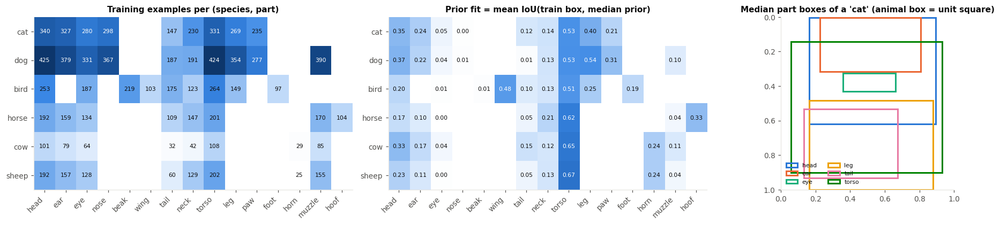

,head,ear,eye,nose,beak,wing,tail,neck,torso,leg,paw,foot,horn,muzzle,hoof
mean prior fit by part,0.27,0.17,0.02,0.01,0.01,0.48,0.08,0.14,0.58,0.39,0.26,0.19,0.24,0.07,0.33


In [7]:
if PRIORS:
    parts_shown = [p for p in PART_MAP if any((c, p) in PRIORS for c in CFG.classes)]
    cnt = np.array([[len(BOXES.get((c, p), [])) or np.nan for p in parts_shown] for c in CFG.classes], float)
    fit = np.array([[PRIOR_FIT.get((c, p), np.nan) for p in parts_shown] for c in CFG.classes], float)
    fig, axes = plt.subplots(1, 3, figsize=(17, 3.9), gridspec_kw={"width_ratios": [1.15, 1.15, 0.9]})
    heatmap(axes[0], cnt, CFG.classes, parts_shown, "Training examples per (species, part)", fmt="{:.0f}")
    heatmap(axes[1], fit, CFG.classes, parts_shown, "Prior fit = mean IoU(train box, median prior)", vmin=0, vmax=1)
    ax = axes[2]; ax.set_xlim(0, 1); ax.set_ylim(1, 0); ax.set_aspect("equal"); ax.grid(False)
    for k, p in enumerate(["head", "ear", "eye", "leg", "tail", "torso"]):
        if ("cat", p) in PRIORS:
            b = PRIORS[("cat", p)]
            ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec=PALETTE[k], lw=2, label=p))
    ax.legend(fontsize=7, loc="lower left", ncol=2); ax.set_title("Median part boxes of a 'cat' (animal box = unit square)")
    plt.tight_layout(); savefig(fig, "02_priors.png"); plt.show()
    display(pd.DataFrame({"mean prior fit by part": pd.Series({p: np.nanmean(fit[:, j]) for j, p in enumerate(parts_shown)})}).round(2).T)

## 2.4 The evaluation set

For each held-out image the notebook keeps the **largest animal** if it is the only animal of its class and covers at
least 8 % of the image. Up to `parts_per_image` parts are then drawn at random from those that are annotated and
at least 0.3 % of the image in size. The prompt is always

> *"Show the **part** of this **species**"*

and the ground truth is the merged Pascal-Part mask. Both systems receive exactly the same images and prompts.

In [8]:
def build_eval_set(files, n_per_class, parts_per_img, seed=CFG.seed):
    rng = random.Random(seed); files = files[:]; rng.shuffle(files)
    samples, count = [], defaultdict(int)
    for f in files:
        if all(count[c] >= n_per_class for c in CFG.classes): break
        objs = load_part_anno(f)
        cand = [o for o in objs if o["cls"] in CFG.classes and count[o["cls"]] < n_per_class]
        if not cand: continue
        o = max(cand, key=lambda x: x["mask"].sum())
        if sum(x["cls"] == o["cls"] for x in objs) != 1: continue            # one instance of the species only
        H, W = o["mask"].shape
        if o["mask"].sum() < CFG.min_obj_frac * H * W: continue
        iid = Path(f).stem
        if iid not in VOC_IMG: continue
        avail = []
        for canon in EVAL_PARTS[o["cls"]]:
            gm = union_part(o, canon)
            if gm.sum() >= CFG.min_part_frac * H * W: avail.append((canon, gm))
        if not avail: continue
        rng.shuffle(avail); count[o["cls"]] += 1
        allp = {c: union_part(o, c) for c in PART_MAP if union_part(o, c).any()} if len(samples) < 12 else None
        for canon, gm in avail[:parts_per_img]:
            samples.append(dict(id=iid, image_path=VOC_IMG[iid], cls=o["cls"], part=canon, gt=gm, obj=o["mask"], all_parts=allp,
                                prompt=f"Show the {canon} of this {o['cls']}"))
    return samples

def build_pet_fallback(n=15):
    import xml.etree.ElementTree as ET
    from torchvision.datasets import OxfordIIITPet
    OxfordIIITPet(root=str(DATA), split="trainval", download=True)
    xmls = sorted(glob.glob(str(DATA / "oxford-iiit-pet/annotations/xmls/*.xml"))); random.Random(CFG.seed).shuffle(xmls)
    cnt, out = defaultdict(int), []
    for x in xmls:
        stem = Path(x).stem; ip = DATA / f"oxford-iiit-pet/images/{stem}.jpg"
        if not ip.exists(): continue
        cls = "cat" if stem[0].isupper() else "dog"
        if cnt[cls] >= n: continue
        r = ET.parse(x).getroot(); bb = r.find("object/bndbox"); sz = r.find("size")
        W, H = int(sz.find("width").text), int(sz.find("height").text)
        b = [int(bb.find(k).text) for k in ("xmin", "ymin", "xmax", "ymax")]
        gt = np.zeros((H, W), bool); gt[b[1]:b[3], b[0]:b[2]] = True; cnt[cls] += 1
        out.append(dict(id=stem, image_path=str(ip), cls=cls, part="head", gt=gt, obj=None, all_parts=None, prompt=f"Show the head of this {cls}"))
    print("FALLBACK mode: the ground truth is the head *bounding box*, so IoU is only a loose proxy.")
    return out

EVAL_SAMPLES = build_eval_set(EVAL_FILES, CFG.n_per_class, CFG.parts_per_image) if USE_PASCAL else build_pet_fallback()
ev = pd.DataFrame([{"cls": s["cls"], "part": s["part"]} for s in EVAL_SAMPLES])
print(f"{len(EVAL_SAMPLES)} prompts on {len({s['id'] for s in EVAL_SAMPLES})} images")
display(pd.crosstab(ev["cls"], ev["part"], margins=True))

137 prompts on 72 images


part,beak,ear,eye,head,horn,leg,neck,nose,tail,wing,All
cls,,,,,,,,,,,
bird,6,0,1,7,0,2,0,0,4,3,23
cat,0,7,2,7,0,5,0,1,2,0,24
cow,0,5,0,10,5,0,0,0,3,0,23
dog,0,5,0,6,0,4,0,7,2,0,24
horse,0,5,0,6,0,0,8,0,5,0,24
sheep,0,5,0,11,0,0,0,0,3,0,19
All,6,27,3,47,5,11,8,8,19,3,137


saved -> outputs/figures/03_ground_truth_examples.png


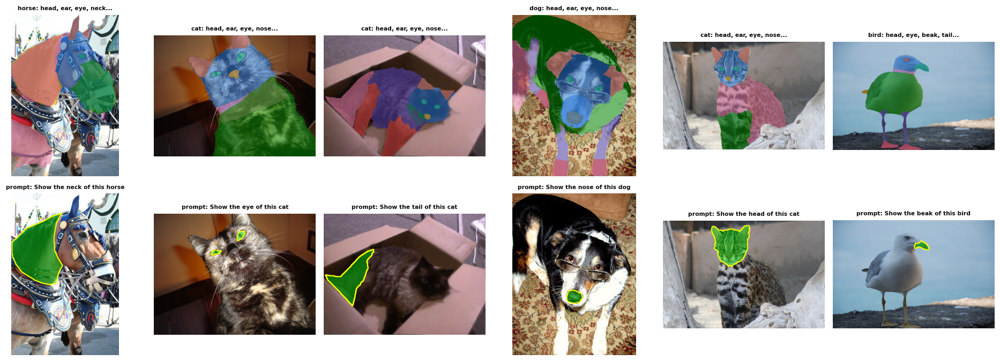

In [9]:
# What the ground truth looks like: every annotated part of the first animals, then the evaluated part highlighted
firsts, seen = [], set()
for s in EVAL_SAMPLES:
    if s["id"] not in seen and s["all_parts"]: firsts.append(s); seen.add(s["id"])
    if len(firsts) == 6: break
if firsts:
    fig, axes = plt.subplots(2, len(firsts), figsize=(2.9 * len(firsts), 6.2))
    for j, s in enumerate(firsts):
        img = Image.open(s["image_path"]).convert("RGB"); arr = np.array(img).copy()
        for k, (c, m) in enumerate(s["all_parts"].items()):
            col = (np.array(matplotlib.colors.to_rgb(PALETTE[k % len(PALETTE)])) * 255)
            arr[m] = (0.45 * arr[m] + 0.55 * col).astype(np.uint8)
        axes[0, j].imshow(arr); axes[0, j].set_title(f"{s['cls']}: " + ", ".join(list(s["all_parts"])[:4]) + "...", fontsize=7)
        axes[1, j].imshow(overlay(img, s["gt"], color=(0, 200, 0))); axes[1, j].set_title(f"prompt: {s['prompt']}", fontsize=7)
        axes[0, j].axis("off"); axes[1, j].axis("off")
    plt.tight_layout(); savefig(fig, "03_ground_truth_examples.png"); plt.show()

## 2.5 Exporting sample inputs and prompts (deliverable)

A set of sample images and their prompts is saved to `outputs/samples/` together with `prompts.csv`.
These are also the examples offered in the interactive interface of §6.

In [10]:
sample_rows, seen = [], set()
for s in EVAL_SAMPLES:
    if s["id"] in seen: continue
    seen.add(s["id"]); dst = SAMPLES / f"{s['id']}.jpg"; shutil.copy(s["image_path"], dst)
    sample_rows.append(dict(image=dst.name, animal=s["cls"], prompt=s["prompt"]))
    if len(sample_rows) == 16: break
pd.DataFrame(sample_rows).to_csv(SAMPLES / "prompts.csv", index=False)
display(pd.DataFrame(sample_rows).head(8))

,image,animal,prompt
0,2010_005484.jpg,horse,Show the neck of this horse
1,2008_007256.jpg,cat,Show the eye of this cat
2,2010_001435.jpg,cat,Show the tail of this cat
3,2009_001869.jpg,dog,Show the nose of this dog
4,2009_001419.jpg,cat,Show the head of this cat
5,2008_003023.jpg,bird,Show the beak of this bird
6,2009_000638.jpg,cat,Show the ear of this cat
7,2010_001665.jpg,dog,Show the leg of this dog


---
# 3. Shared components

## 3.1 Text utilities: prompt parser and knowledge base

**Rule-based parser (System A).** A synonym dictionary maps words to a canonical part and, optionally, a species
("wings" → `wing`, "bill" → `beak`, "body" → `torso`). A prompt without a known part is rejected with a message
that lists the supported parts. `normalize_part` applies the same dictionary to *any* text; it is also used to
check whether **System B's** free-text answer names the requested part (§7.1).

**Knowledge base (System A).** Each of the 15 parts has a hand-written *appearance* sentence and a *function*
sentence, with 11 species-specific overrides (bird wing, cat ear, cow horn, ...). It never looks at the image, so
every cat ear receives the same text. It is the baseline against which the VLM's context-aware text is compared.

In [11]:
SPECIES_WORDS = {"cat": "cat", "kitten": "cat", "dog": "dog", "puppy": "dog", "bird": "bird", "horse": "horse", "pony": "horse",
                 "cow": "cow", "cattle": "cow", "sheep": "sheep", "lamb": "sheep", "elephant": "elephant", "bear": "bear",
                 "zebra": "zebra", "giraffe": "giraffe"}
PART_WORDS = {"head": "head", "face": "head", "ear": "ear", "ears": "ear", "eye": "eye", "eyes": "eye", "nose": "nose", "beak": "beak",
              "bill": "beak", "wing": "wing", "wings": "wing", "tail": "tail", "neck": "neck", "torso": "torso", "body": "torso",
              "leg": "leg", "legs": "leg", "paw": "paw", "paws": "paw", "foot": "foot", "feet": "foot", "horn": "horn", "horns": "horn",
              "muzzle": "muzzle", "snout": "muzzle", "hoof": "hoof", "hooves": "hoof"}

def parse_prompt_rule(prompt):
    toks = re.findall(r"[a-z]+", prompt.lower())
    part = next((PART_WORDS[t] for t in toks if t in PART_WORDS), None)
    species = next((SPECIES_WORDS[t] for t in toks if t in SPECIES_WORDS), None)
    return part, species

def normalize_part(text): return parse_prompt_rule(text or "")[0]

KB = {
 "head":  ("The head is the front end of the body, carrying the eyes, ears, nose and mouth, with a shape and covering that differ by species.",
           "It houses the brain and the main sense organs and the mouth for feeding, so it guides perception, feeding and communication."),
 "ear":   ("Ears are paired, usually upright or drooping flaps on the sides or top of the head, covered in fur or skin.",
           "They collect sound and help locate where it comes from; in many mammals they also help with balance and heat loss."),
 "eye":   ("Eyes are small, rounded, paired organs set in the face, with a coloured iris and a dark pupil.",
           "They detect light and form images, letting the animal find food, spot predators and navigate."),
 "nose":  ("The nose is a moist or hairless tip at the front of the face with two nostrils.",
           "It is used for breathing and smelling; the sense of smell guides foraging, social recognition and danger detection."),
 "beak":  ("The beak is a hard, toothless, pointed projection at the front of the head, made of keratin.",
           "Birds use it to pick up, crack or tear food, preen feathers, build nests and defend themselves."),
 "wing":  ("Wings are paired limbs covered with layered feathers that form a broad, light surface.",
           "They generate lift and thrust for flight, and also help with balance, display and temperature regulation."),
 "tail":  ("The tail is a flexible extension at the rear of the body, covered with fur, hair or feathers.",
           "It aids balance and steering, signals mood or warning, and can swat insects or help keep warm."),
 "neck":  ("The neck is the narrow, muscular region connecting the head to the body.",
           "It supports and moves the head, and carries the spinal cord, windpipe, food pipe and blood vessels."),
 "torso": ("The torso (body) is the large central part of the animal that holds the main organs, covered in fur or feathers.",
           "It protects vital organs such as the heart, lungs and digestive system and anchors the limbs."),
 "leg":   ("Legs are paired, jointed limbs, often slender and muscular, ending in feet, paws or hooves.",
           "They support the body weight and provide locomotion for walking, running, jumping or perching."),
 "paw":   ("Paws are padded feet, often with fur and claws at the tips of the toes.",
           "They cushion steps, give grip, and claws are used for climbing, digging, and catching prey."),
 "foot":  ("Feet are the lower ends of the legs, with toes and often scaly skin or claws.",
           "They provide grip and support for walking, perching or swimming."),
 "horn":  ("Horns are hard, curved or pointed bony outgrowths on the head, covered in keratin.",
           "They are used for defence, dominance contests between males and sometimes for heat regulation."),
 "muzzle": ("The muzzle is the forward-projecting part of the face containing the nose and mouth.",
            "It is used for smelling, feeding and grooming."),
 "hoof":  ("Hooves are hard, horny coverings around the tips of the toes.",
           "They protect the toes and give traction for running on firm ground."),
}
SPECIES_KB = {
 ("bird", "wing"):  ("Bird wings are covered with overlapping flight feathers that form a broad, light surface.",
                     "They provide lift and thrust for flight and also assist balance and courtship display."),
 ("bird", "beak"):  ("The beak is a lightweight horny structure whose shape is adapted to the bird's diet.",
                     "It replaces teeth for picking, cracking or tearing food and for preening."),
 ("bird", "leg"):   ("Bird legs are thin and often scaly, ending in clawed toes.",
                     "They support the body, and are used for perching, walking, swimming or catching prey."),
 ("bird", "tail"):  ("The bird's tail is a fan of long feathers at the rear.", "It steers and brakes in flight and is used in displays."),
 ("cat", "ear"):    ("Cat ears are triangular, upright and mobile, lined with soft fur.",
                     "They swivel independently to pinpoint faint sounds such as prey and indicate mood."),
 ("dog", "ear"):    ("Dog ears may be erect, folded or drooping depending on breed and are covered in fur.",
                     "They detect a wide range of sound frequencies and express emotion."),
 ("cat", "tail"):   ("A cat's tail is long, flexible and furry.", "It helps balance during jumps and signals mood."),
 ("dog", "tail"):   ("A dog's tail is a furred extension of the spine, with shape varying by breed.", "It is used for balance and social signalling such as wagging."),
 ("horse", "leg"):  ("Horse legs are long, slender and muscular, ending in a single hoof.", "They give speed and endurance for fast running."),
 ("cow", "horn"):   ("Cow horns are curved, hard outgrowths that sit on the sides of the head.", "They are used for defence and establishing social rank."),
 ("sheep", "horn"): ("Sheep horns are thick and often spiralled, covered with keratin.", "They are used in fights between males and for defence."),
}
def kb_description(species, part):
    if part not in KB: return f"No predefined description for '{part}'."
    a, f = SPECIES_KB.get((species, part), KB[part])
    return f"Appearance: {a} Function: {f}"

def reference_description(species, part):          # reference text for the text-similarity metric (§7.2)
    a, f = SPECIES_KB.get((species, part), KB.get(part, ("", "")))
    return f"{a} {f}"

print("supported parts:", sorted(set(PART_WORDS.values())))
print(parse_prompt_rule("Identify the ears of this cat"), parse_prompt_rule("Show the bill of the bird"))

supported parts: ['beak', 'ear', 'eye', 'foot', 'head', 'hoof', 'horn', 'leg', 'muzzle', 'neck', 'nose', 'paw', 'tail', 'torso', 'wing']
('ear', 'cat') ('beak', 'bird')


## 3.2 Model wrappers

| Wrapper | Model | Role |
|---|---|---|
| `SAM2Wrapper` | **SAM 2.1 Hiera-L** (`facebook/sam2.1-hiera-large`) | box → mask. The image embedding is computed once per image (`set_image`); each box then costs only a light decoder pass. Shared by both systems. |
| `QwenVLM` | **Qwen2.5-VL-3B-Instruct** | one model, three prompts: interpret, ground, describe. Returns the size of the image the model actually saw, so that its box coordinates can be mapped back to the original (§5). |
| `TextOnlyLLM` | Qwen2.5-1.5B-Instruct | *optional* System A description generator that receives only the words "species" and "part" (never the image). Switched off by default; the knowledge base is used. |
| YOLO | **YOLOv8x** (COCO) | detects the animal (ten COCO animal classes). |

Half precision (bfloat16 where the GPU supports it, otherwise float16) is used for SAM 2 and the VLM.

In [12]:
from sam2.sam2_image_predictor import SAM2ImagePredictor
from ultralytics import YOLO
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor, AutoModelForCausalLM, AutoTokenizer
from qwen_vl_utils import process_vision_info

class SAM2Wrapper:
    def __init__(self, model_id):
        self.pred = SAM2ImagePredictor.from_pretrained(model_id)
        self.params_m = count_params(self.pred.model)
    def set_image(self, rgb):
        with torch.inference_mode(), torch.autocast("cuda", dtype=AMP_DTYPE):
            self.pred.set_image(rgb)
    def segment(self, box, multimask=False):
        # box: [x1,y1,x2,y2] in pixels  ->  (masks (C,H,W) bool, scores (C,))
        with torch.inference_mode(), torch.autocast("cuda", dtype=AMP_DTYPE):
            masks, scores, _ = self.pred.predict(box=np.asarray(box, dtype=np.float32), multimask_output=multimask)
        if masks.ndim == 2: masks = masks[None]
        return masks > 0.5, np.asarray(scores).reshape(-1)

class QwenVLM:
    def __init__(self, name, max_pixels):
        self.model = Qwen2_5_VLForConditionalGeneration.from_pretrained(name, torch_dtype=AMP_DTYPE, device_map="auto").eval()
        self.proc = AutoProcessor.from_pretrained(name)
        self.max_pixels = max_pixels
        self.params_m = count_params(self.model)
    @torch.no_grad()
    def chat(self, image, text, max_new_tokens=200):
        msgs = [{"role": "user", "content": [{"type": "image", "image": image, "max_pixels": self.max_pixels},
                                              {"type": "text", "text": text}]}]
        prompt = self.proc.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        imgs, _ = process_vision_info(msgs)
        inp = self.proc(text=[prompt], images=imgs, padding=True, return_tensors="pt").to(self.model.device)
        out = self.model.generate(**inp, max_new_tokens=max_new_tokens, do_sample=False)        # greedy -> deterministic
        txt = self.proc.batch_decode(out[:, inp.input_ids.shape[1]:], skip_special_tokens=True)[0]
        g = inp["image_grid_thw"][0]                      # (t, h/14, w/14): the size of the image the model really saw
        return txt.strip(), (int(g[1]) * 14, int(g[2]) * 14)

class TextOnlyLLM:                                        # System A option: a language model that never sees the image
    def __init__(self, name="Qwen/Qwen2.5-1.5B-Instruct"):
        self.tok = AutoTokenizer.from_pretrained(name)
        self.model = AutoModelForCausalLM.from_pretrained(name, torch_dtype=AMP_DTYPE, device_map="auto").eval()
    @torch.no_grad()
    def describe(self, species, part):
        msgs = [{"role": "user", "content": f"In two short sentences, describe the typical appearance and the biological function of the {part} of a {species}."}]
        ids = self.tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt").to(self.model.device)
        out = self.model.generate(ids, max_new_tokens=90, do_sample=False)
        return self.tok.decode(out[0, ids.shape[1]:], skip_special_tokens=True).strip()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## 3.3 Loading the models and measuring what they cost

Weights are loaded one by one and the GPU memory taken by each is recorded. The table is reused in §8.8.

In [13]:
def gpu_mb():
    torch.cuda.synchronize(); return torch.cuda.memory_allocated() / 2**20

mrows = []
m0 = gpu_mb(); SAM = SAM2Wrapper(CFG.sam_id);                  mrows.append(("SAM 2.1 Hiera-L", "box -> mask (A and B)", SAM.params_m, gpu_mb() - m0))
m0 = gpu_mb(); YOLO_MODEL = YOLO(CFG.yolo_weights); YOLO_MODEL.predict(np.zeros((64, 64, 3), np.uint8), verbose=False)
yolo_params = count_params(YOLO_MODEL.model);                  mrows.append(("YOLOv8x", "animal detector (A)", yolo_params, gpu_mb() - m0))
m0 = gpu_mb(); VLM = QwenVLM(CFG.vlm_id, CFG.vlm_max_pixels); mrows.append(("Qwen2.5-VL-3B-Instruct", "parse + ground + describe (B)", VLM.params_m, gpu_mb() - m0))
TEXT_LLM = None                    # set TEXT_LLM = TextOnlyLLM() to let System A use a text-only LLM instead of the knowledge base
MODEL_TABLE = pd.DataFrame(mrows, columns=["model", "role", "parameters (M)", "GPU memory after loading (MB)"]).round(0)
PARAMS = {A_: SAM.params_m + yolo_params, B_: SAM.params_m + VLM.params_m}
display(MODEL_TABLE)
print({k: f"{v:,.0f} M" for k, v in PARAMS.items()})

sam2.1_hiera_large.pt: reconstructing file:   0%|          |  0.00B /  898MB            

sam2.1_hiera_large.pt: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

...

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

,model,role,parameters (M),GPU memory after loading (MB)
0,SAM 2.1 Hiera-L,box -> mask (A and B),224.0,1001.0
1,YOLOv8x,animal detector (A),68.0,262.0
2,Qwen2.5-VL-3B-Instruct,parse + ground + describe (B),3755.0,7162.0


{'A_noVLM': '293 M', 'B_VLM': '3,979 M'}


---
# 4. System A: conventional computer vision, no vision-language model

```
 prompt ──► rule-based parser ───────────────┬────────────────────────────────────────┐
                                             │ (part name)                             │ (species, part)
 image ───► YOLOv8x ──► animal box ──► learned part prior ──► part box(es) ──► SAM 2 ──► mask ──► knowledge-base text
                        (species)       (rescaled to the box)  (paired parts split)     (best of 3)
```

1. **Parse** the prompt into (part, optional species).
2. **Detect** the animal with YOLOv8x; if the prompt names a species, matching detections are preferred, otherwise
   the one with the highest *confidence × area* is used. (Ultralytics expects BGR arrays, hence `[:, :, ::-1]`.)
3. **Place** the part: take the learned prior for (species, part), rescale it to the animal box. Species without
   Pascal-Part data borrow a related prior (elephant→cow, bear→dog, zebra and giraffe→horse); a small hand-written
   table is the last fallback.
4. **Paired parts** (ear, eye, wing, horn): the prior box spans *both* parts, so it is split into a left and a right
   half and each half is prompted separately; the masks are united.
5. **Segment**: SAM 2 returns three candidate masks $m_k$ with predicted quality $q_k$ for each box. The
   candidate that maximises

$$s_k=q_k+\mathrm{IoU}_{\text{box}}\big(\mathrm{bbox}(m_k),\mathbf B\big)-\lambda\max\!\Big(0,\ \tfrac{|m_k|}{|\mathbf B|}-1.5\Big)\qquad(\lambda=0.3)$$

   is kept ($\mathbf B$ = prompt box): it should be confident, should fill the box and should not spill far
   outside it. The final mask is clipped to the YOLO animal box.
6. **Describe**: knowledge-base entry (or, optionally, the text-only LLM).

Two flags exist only for the ablations of §9: `use_learned_priors=False` (hand-written priors) and
`split_paired=False` (one box for both ears/eyes/wings).

In [14]:
ANIMALS = {"bird", "cat", "dog", "horse", "sheep", "cow", "elephant", "bear", "zebra", "giraffe"}
COCO2PRIOR = {"elephant": "cow", "bear": "dog", "zebra": "horse", "giraffe": "horse"}
PAIRED = {"ear", "eye", "wing", "horn"}
HAND_PRIORS = {"head": [0.0, 0.0, 0.45, 0.40], "ear": [0.05, 0.0, 0.45, 0.20], "eye": [0.05, 0.05, 0.35, 0.22], "nose": [0.0, 0.1, 0.2, 0.3],
               "beak": [0.0, 0.05, 0.25, 0.3], "wing": [0.2, 0.2, 0.8, 0.75], "tail": [0.7, 0.2, 1.0, 0.6], "neck": [0.1, 0.1, 0.4, 0.5],
               "torso": [0.2, 0.25, 0.8, 0.8], "leg": [0.1, 0.6, 0.9, 1.0], "paw": [0.1, 0.85, 0.9, 1.0], "foot": [0.1, 0.85, 0.9, 1.0],
               "horn": [0.0, 0.0, 0.4, 0.15], "muzzle": [0.0, 0.1, 0.25, 0.35], "hoof": [0.1, 0.9, 0.9, 1.0]}

class SystemA:
    name = "A: YOLO + priors + SAM2"
    def __init__(self, sam, yolo, priors, text_llm=None, use_learned_priors=True, split_paired=True):
        self.sam, self.yolo, self.priors, self.text_llm = sam, yolo, priors, text_llm
        self.use_learned_priors, self.split_paired = use_learned_priors, split_paired
        self.last = {}

    def detect(self, rgb, hint=None):
        r = self.yolo.predict(rgb[:, :, ::-1], conf=CFG.yolo_conf, verbose=False)[0]
        cands = []
        for b, c, p in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy(), r.boxes.conf.cpu().numpy()):
            nm = r.names[int(c)]
            if nm in ANIMALS: cands.append((nm, b, float(p) * (b[2] - b[0]) * (b[3] - b[1])))
        if hint and any(c[0] == hint for c in cands): cands = [c for c in cands if c[0] == hint]
        return max(cands, key=lambda c: c[2]) if cands else None

    def prior_box(self, cls, part):
        c = COCO2PRIOR.get(cls, cls)
        if self.use_learned_priors and (c, part) in self.priors: return self.priors[(c, part)]
        return HAND_PRIORS.get(part, [0.25, 0.25, 0.75, 0.75])

    def run(self, pil, prompt):
        t0 = time.time(); rgb = np.array(pil.convert("RGB")); H, W = rgb.shape[:2]
        part, hint = parse_prompt_rule(prompt)
        if part is None:
            return dict(error=f"Could not find a supported body part in the prompt. Supported: {sorted(set(PART_WORDS.values()))}")
        det = self.detect(rgb, hint)
        if det is None: return dict(error="No animal detected by YOLO.", parsed_part=part)
        species, abox, _ = det
        pb = self.prior_box(species, part); ax1, ay1, aw, ah = abox[0], abox[1], abox[2] - abox[0], abox[3] - abox[1]
        pbox = [ax1 + pb[0] * aw, ay1 + pb[1] * ah, ax1 + pb[2] * aw, ay1 + pb[3] * ah]
        boxes = [pbox]
        if part in PAIRED and self.split_paired:
            mx = (pbox[0] + pbox[2]) / 2; boxes = [[pbox[0], pbox[1], mx, pbox[3]], [mx, pbox[1], pbox[2], pbox[3]]]
        self.sam.set_image(rgb)
        full = np.zeros((H, W), bool); used, cand_log = [], []
        for bx in boxes:
            bx = [max(0, bx[0]), max(0, bx[1]), min(W - 1, bx[2]), min(H - 1, bx[3])]
            if bx[2] - bx[0] < 4 or bx[3] - bx[1] < 4: continue
            masks, scores = self.sam.segment(bx, multimask=True)
            parea = (bx[2] - bx[0]) * (bx[3] - bx[1]); best, bs, bk = None, -1e9, -1
            for k, (m, sc) in enumerate(zip(masks, scores)):
                mb = mask_bbox(m)
                if mb is None: continue
                s = sc + box_iou(mb, bx) - CFG.sam_cand_penalty * max(0.0, m.sum() / parea - 1.5)
                if s > bs: best, bs, bk = m, s, k
            cand_log.append(dict(box=bx, masks=masks, scores=scores, chosen=bk))
            if best is not None: full |= best; used.append(bx)
        ab = np.zeros((H, W), bool); ab[int(abox[1]):int(abox[3]), int(abox[0]):int(abox[2])] = True
        full &= ab                                                              # stay inside the detected animal
        self.last = dict(abox=abox, cands=cand_log)
        t1 = time.time()
        desc = self.text_llm.describe(species, part) if self.text_llm else kb_description(species, part)
        return dict(mask=full if full.any() else None, boxes=used, description=desc, species=species, parsed_part=part,
                    t_seg=t1 - t0, t_desc=time.time() - t1, raw=dict(animal_box=[float(v) for v in abox]))

saved -> outputs/figures/04_system_a_walkthrough.png


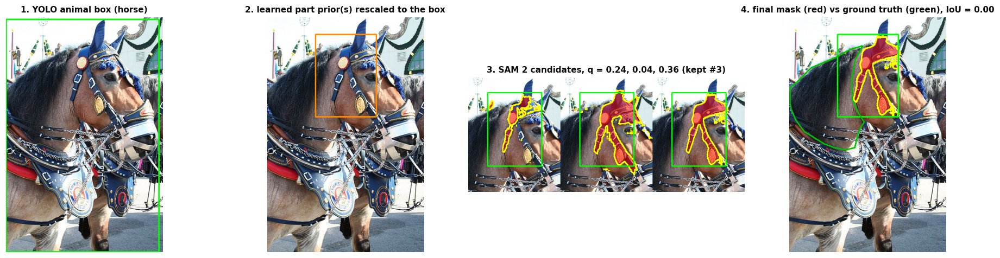

Description: Appearance: The neck is the narrow, muscular region connecting the head to the body. Function: It supports and moves the head, and carries the spinal cord, windpipe, food pipe and blood vessels.


In [15]:
SYS_A = SystemA(SAM, YOLO_MODEL, PRIORS, TEXT_LLM)

def crop_box(arr, box, m=0.35):
    H, W = arr.shape[:2]; w, h = box[2] - box[0], box[3] - box[1]
    x1, y1, x2, y2 = int(max(0, box[0] - m * w)), int(max(0, box[1] - m * h)), int(min(W, box[2] + m * w)), int(min(H, box[3] + m * h))
    return arr[y1:y2, x1:x2]

def demo_system_a(i=0):
    # step-by-step view of System A on one prompt
    s = EVAL_SAMPLES[i]; img = Image.open(s["image_path"]).convert("RGB"); r = SYS_A.run(img, s["prompt"])
    if "error" in r: print(r["error"]); return
    dbg = SYS_A.last; cand = dbg["cands"][0]
    fig, ax = plt.subplots(1, 4, figsize=(18, 4.4))
    ax[0].imshow(overlay(img, None, [dbg["abox"]])); ax[0].set_title(f"1. YOLO animal box ({r['species']})")
    ax[1].imshow(overlay(img, None, [c["box"] for c in dbg["cands"]], box_color=(255, 140, 0))); ax[1].set_title("2. learned part prior(s) rescaled to the box")
    tiles = [crop_box(np.array(overlay(img, m, [cand["box"]])), cand["box"]) for m in cand["masks"]]
    hh = min(t.shape[0] for t in tiles); ww = min(t.shape[1] for t in tiles)
    ax[2].imshow(np.hstack([cv2.resize(t, (ww, hh)) for t in tiles]))
    ax[2].set_title("3. SAM 2 candidates, q = " + ", ".join(f"{q:.2f}" for q in cand["scores"]) + f" (kept #{cand['chosen'] + 1})")
    ax[3].imshow(overlay(img, r["mask"], r["boxes"])); ax[3].contour(s["gt"], levels=[0.5], colors="#00c000", linewidths=1.6)
    ax[3].set_title(f"4. final mask (red) vs ground truth (green), IoU = {iou_dice(r['mask'], s['gt'])[0]:.2f}")
    for a in ax: a.axis("off")
    plt.tight_layout(); savefig(fig, "04_system_a_walkthrough.png"); plt.show()
    print("Description:", r["description"])

demo_system_a(0)

---
# 5. System B: with a vision-language model

```
 image + prompt ─► VLM call 1 ─► {"animal","part","visible"} ─► VLM call 2 ─► part bounding boxes ─► SAM 2 ─► mask
                   (interpret)                                    (ground)      (rescaled)                     │
                                                       crop around the mask ─► VLM call 3 (describe) ◄─────────┘
```

One Qwen2.5-VL-3B model is called three times with different instructions (greedy decoding, so the output is
deterministic):

| Call | Instruction (abridged) | Output used for |
|---|---|---|
| 1. Interpret | *"A user asked: ⟨prompt⟩. Look at the image and answer ONLY with JSON: animal, part, visible."* | the animal and part names (no dictionary, any wording) |
| 2. Ground | *"Locate every visible ⟨part⟩ of the ⟨animal⟩ in the image and output bbox coordinates in JSON format."* | up to four boxes |
| 3. Describe | *"This image shows the ⟨part⟩ of a ⟨animal⟩ (cropped from a larger photo). In 2-3 sentences: first how it actually looks (colour, texture, shape, size), then its main biological function for this kind of animal."* | context-aware description |

**Coordinate rescaling.** Qwen2.5-VL returns boxes in the pixel grid of the image it *received*, which was resized to
$(h_r,w_r)=14\cdot(g_h,g_w)$ with $(g_h,g_w)$ the patch grid reported by the processor. A box is mapped back to the
$W\times H$ original with $x\leftarrow x\,W/w_r$, $y\leftarrow y\,H/h_r$. Skipping this step silently shifts every box
whenever the image is resized.

**Filtering.** At most four boxes are kept; boxes covering more than 90 % of the image are discarded (the VLM
sometimes answers with the whole image) unless the part is the torso. If nothing is left, the system reports that
the part could not be localised instead of guessing.

**Description input.** The VLM sees a crop around the mask enlarged by 15 % of its size plus 8 px, so it
describes this particular part together with a little context, not a generic one.

In [16]:
PARSE_PROMPT  = 'A user asked: "{prompt}". Look at the image and answer ONLY with JSON: {{"animal": "<species in the image>", "part": "<requested body part, singular, lowercase>", "visible": true}}'
GROUND_PROMPT = "Locate every visible {part} of the {animal} in the image and output bbox coordinates in JSON format."
DESC_PROMPT   = ("This image shows the {part} of a {animal} (cropped from a larger photo). In 2-3 sentences: first describe how it actually "
                 "looks in this image (colour, texture, shape, size), then explain its main biological function for this kind of animal. Be concise and factual.")

def extract_json(txt):
    m = re.search(r"\{.*?\}", txt, re.S)
    try: return json.loads(m.group(0)) if m else {}
    except Exception: return {}

def parse_boxes(txt, rh, rw, W, H):
    # all [x1,y1,x2,y2] lists in the VLM output -> boxes in ORIGINAL pixel coordinates
    num = r"(-?\d+(?:\.\d+)?)"
    out = []
    for m in re.finditer(r"\[\s*" + r"\s*,\s*".join([num] * 4) + r"\s*\]", txt):
        x1, y1, x2, y2 = [float(v) for v in m.groups()]
        x1, x2 = x1 * W / rw, x2 * W / rw; y1, y2 = y1 * H / rh, y2 * H / rh
        x1, y1, x2, y2 = max(0, min(x1, x2)), max(0, min(y1, y2)), min(W - 1, max(x1, x2)), min(H - 1, max(y1, y2))
        if x2 - x1 > 3 and y2 - y1 > 3: out.append([x1, y1, x2, y2])
    return out[:4]

class SystemB:
    name = "B: Qwen2.5-VL + SAM2"
    def __init__(self, sam, vlm): self.sam, self.vlm = sam, vlm

    def run(self, pil, prompt):
        t0 = time.time(); pil = pil.convert("RGB"); W, H = pil.size
        raw1, _ = self.vlm.chat(pil, PARSE_PROMPT.format(prompt=prompt), max_new_tokens=60)
        j = extract_json(raw1)
        animal = str(j.get("animal", "animal")).lower(); part = str(j.get("part") or prompt).lower()
        raw2, (rh, rw) = self.vlm.chat(pil, GROUND_PROMPT.format(part=part, animal=animal), max_new_tokens=160)
        raw = dict(interpret=raw1, ground=raw2, model_input_hw=[rh, rw])
        boxes = parse_boxes(raw2, rh, rw, W, H)
        if normalize_part(part) != "torso":                                          # drop "whole image" answers
            boxes = [b for b in boxes if (b[2] - b[0]) * (b[3] - b[1]) < 0.9 * W * H]
        if not boxes:
            return dict(error=f"The VLM could not localise '{part}'. (raw output: {raw2[:120]})", parsed_part=part, species=animal, raw=raw)
        self.sam.set_image(np.array(pil)); full = np.zeros((H, W), bool)
        for b in boxes:
            m, _ = self.sam.segment(b, multimask=False); full |= m[0]
        t1 = time.time()
        bb = mask_bbox(full) or tuple(map(int, boxes[0]))
        mx, my = int(0.15 * (bb[2] - bb[0])) + 8, int(0.15 * (bb[3] - bb[1])) + 8
        crop = pil.crop((max(0, bb[0] - mx), max(0, bb[1] - my), min(W, bb[2] + mx), min(H, bb[3] + my)))
        desc, _ = self.vlm.chat(crop, DESC_PROMPT.format(part=part, animal=animal), max_new_tokens=130)
        return dict(mask=full if full.any() else None, boxes=boxes, description=desc, species=animal, parsed_part=part,
                    t_seg=t1 - t0, t_desc=time.time() - t1, raw=raw)

VLM call 1 (interpret): ```json
{
  "animal": "horse",
  "part": "neck",
  "visible": true
}
```
VLM call 2 (ground)   : ```json
[
	{"bbox_2d": [1, 60, 335, 498], "label": "visible neck of the horse"}
]
``` | model input (h, w): [504, 336]
saved -> outputs/figures/05_system_b_walkthrough.png


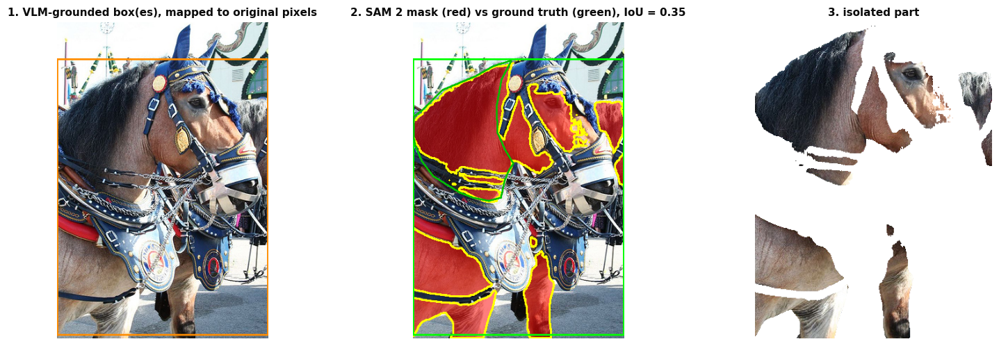


Description: The horse's neck is covered with a blue and white bridle adorned with various decorative elements such as gold medallions and ribbons. The bridle fits snugly around the horse's head, providing control and guidance during riding. Its primary biological function is to help the rider maintain control over the horse while ensuring the horse remains calm and responsive.


In [17]:
SYS_B = SystemB(SAM, VLM)

def demo_system_b(i=0):
    s = EVAL_SAMPLES[i]; img = Image.open(s["image_path"]).convert("RGB"); r = SYS_B.run(img, s["prompt"])
    print("VLM call 1 (interpret):", r["raw"]["interpret"]); print("VLM call 2 (ground)   :", r["raw"]["ground"], "| model input (h, w):", r["raw"]["model_input_hw"])
    if "error" in r: print(r["error"]); return
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
    ax[0].imshow(overlay(img, None, r["boxes"], box_color=(255, 140, 0))); ax[0].set_title("1. VLM-grounded box(es), mapped to original pixels")
    ax[1].imshow(overlay(img, r["mask"], r["boxes"])); ax[1].contour(s["gt"], levels=[0.5], colors="#00c000", linewidths=1.6)
    ax[1].set_title(f"2. SAM 2 mask (red) vs ground truth (green), IoU = {iou_dice(r['mask'], s['gt'])[0]:.2f}")
    cut = make_cutout(img, r["mask"]); bg = Image.new("RGB", cut.size, "white"); bg.paste(cut, mask=cut.split()[3]); ax[2].imshow(bg); ax[2].set_title("3. isolated part")
    for a in ax: a.axis("off")
    plt.tight_layout(); savefig(fig, "05_system_b_walkthrough.png"); plt.show()
    print("\nDescription:", r["description"])

demo_system_b(0)

---
# 6. Interactive user interface

A **Gradio** app (a public link is created in Colab) lets the user upload any animal photo, type a prompt and run
System A, System B or both. For each system it shows the **overlay** (mask and boxes), the **isolated part**
(cut-out on a transparent background), the **description**, the detected animal / parsed part and the
**processing time**. Examples taken from the evaluation set are offered below the form.

In [18]:
import gradio as gr

def pack(r, pil):
    if "error" in r: return None, None, "⚠️ " + r["error"]
    m = r.get("mask")
    if m is None: return None, None, "No mask produced."
    txt = (f"**Animal:** {r['species']}  |  **Part:** {r['parsed_part']}  |  "
           f"**Time:** segmentation {r['t_seg']:.2f} s + description {r['t_desc']:.2f} s\n\n{r['description']}")
    return overlay(pil, m, r["boxes"]), make_cutout(pil, m), txt

def ui_run(img, prompt, which):
    if img is None or not prompt: return [None, None, "Upload an image and enter a prompt."] * 2
    img = img.convert("RGB"); out = []
    for key, sysx in (("A", SYS_A), ("B", SYS_B)):
        if which in ("Both", f"{key} only"):
            try: out += list(pack(sysx.run(img, prompt), img))
            except Exception as e: out += [None, None, f"Error: {e}"]
        else: out += [None, None, "(not run)"]
    return out

with gr.Blocks(title="Prompt-guided animal part segmentation") as demo:
    gr.Markdown("# 🐾 Animal body-part segmentation & description\nUpload an animal photo and ask, e.g., *“Show the wings of this bird”* or *“Identify the ears of this cat”*.")
    with gr.Row():
        inp = gr.Image(type="pil", label="Animal image")
        with gr.Column():
            prm = gr.Textbox(label="Prompt", value="Show the ears of this animal")
            which = gr.Radio(["Both", "A only", "B only"], value="Both", label="System")
            btn = gr.Button("Segment & describe", variant="primary")
    with gr.Row():
        with gr.Column():
            gr.Markdown("### System A: YOLO + learned priors + SAM 2 (no VLM)")
            a_ov = gr.Image(label="Overlay"); a_cut = gr.Image(label="Isolated part", image_mode="RGBA"); a_tx = gr.Markdown()
        with gr.Column():
            gr.Markdown("### System B: Qwen2.5-VL + SAM 2")
            b_ov = gr.Image(label="Overlay"); b_cut = gr.Image(label="Isolated part", image_mode="RGBA"); b_tx = gr.Markdown()
    btn.click(ui_run, [inp, prm, which], [a_ov, a_cut, a_tx, b_ov, b_cut, b_tx])
    ex = [[str(SAMPLES / r["image"]), r["prompt"], "Both"] for r in sample_rows[:6]]
    if ex: gr.Examples(ex, [inp, prm, which])
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0c9283c4e5cc87644e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
# 7. Comparative evaluation protocol

## 7.1 Metrics

Both systems run on **identical images and prompts**. A *warm-up call* on the first sample is excluded from the
timings. Failures (no animal found, no box, empty mask) count as IoU = Dice = 0 so that they lower the average.

**Segmentation** (predicted mask $P$, ground truth $G$):
$$\mathrm{IoU}=\frac{|P\cap G|}{|P\cup G|},\qquad \mathrm{Dice}=\frac{2|P\cap G|}{|P|+|G|}$$
plus the share of samples with IoU ≥ 0.5, and a 95 % bootstrap confidence interval of the mean.

**Prompt following** (is the answer *about the right thing*?):
* **part parsed** – the part the system names equals the requested part;
* **species ok** – the species the system names equals the true species;
* **mask produced** – the system returned a non-empty mask;
* **pointing-game hit** – the *centroid* of the predicted mask lies inside the bounding box of the ground-truth part.
  This separates *wrong place* from *right place, imprecise boundary*.

**Outcome taxonomy** of every sample (used in §8.4): *no mask* · *wrong region* (no hit) · *right region, imprecise mask*
(hit, IoU < 0.5) · *success* (IoU ≥ 0.5).

**Description quality** (automatic proxies, since no human reference exists for photos):
* **CLIP score** – cosine similarity ×100 between the description and the tight crop of the segmented part
  (CLIP ViT-B/32). Measures whether the *text fits the picture*.
* **Reference similarity** – MiniLM cosine similarity to the knowledge-base text. ⚠️ *Circular for System A*,
  whose text *is* the reference, so it is reported but **not** used to rank the systems.
* **Names the species / mentions a colour** – does the text contain image-specific information?
* **Unique-text ratio** – share of distinct descriptions. A knowledge base repeats itself by construction.
* A **human rating template** (30 random outputs, three 1–5 scales) is exported.

**Compute**: wall-clock time of a whole call (with GPU synchronisation, split into segmentation and description),
extra GPU memory above the loaded weights (peak − allocated before the call), and parameter count.

**Statistics**: paired **Wilcoxon signed-rank test** on per-sample IoU (overall and per part / species), and
win / tie / loss counts (|ΔIoU| ≤ 0.01 counts as a tie).

In [19]:
from transformers import CLIPModel, CLIPProcessor
from sentence_transformers import SentenceTransformer, util

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEV).eval()
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
sbert = SentenceTransformer("all-MiniLM-L6-v2", device="cuda")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [20]:
COLORS = {"black", "white", "brown", "grey", "gray", "orange", "yellow", "red", "tan", "beige", "golden", "blue", "green", "cream", "spotted", "striped", "dark", "light", "tabby"}

@torch.no_grad()
def clip_score(img, text):
    inp = clip_proc(text=[text], images=img, return_tensors="pt", padding=True, truncation=True, max_length=77).to(DEV)
    o = clip(**inp); return 100 * float(torch.nn.functional.cosine_similarity(o.image_embeds, o.text_embeds))

def text_sim(a, b):
    e = sbert.encode([a, b], convert_to_tensor=True); return float(util.cos_sim(e[0], e[1]))

def desc_metrics(desc, cutout, cls, part):
    d = re.sub(r"^Appearance:\s*", "", desc)
    return dict(clip=clip_score(cutout.convert("RGB"), d), sim_ref=text_sim(d, reference_description(cls, part)),
                species_mention=float(cls in desc.lower()), color_mention=float(any(c in desc.lower() for c in COLORS)), n_words=len(desc.split()))

## 7.2 Running the evaluation

The loop is **resumable**: results are appended to `per_sample_main.csv` every 10 prompts and each predicted mask is
saved as a PNG, so a Colab disconnection costs at most ten prompts. Re-run the cell to continue. Delete
`outputs/results/per_sample_main.csv` to start over.

In [21]:
def evaluate(systems, samples, tag="main"):
    csvp = RES / f"per_sample_{tag}.csv"
    rows = pd.read_csv(csvp).to_dict("records") if csvp.exists() else []
    done = {(int(r["idx"]), r["system"]) for r in rows}
    for name in systems:
        (MASKS / name).mkdir(exist_ok=True); (CUTS / name).mkdir(exist_ok=True)
    s0 = samples[0]; img0 = Image.open(s0["image_path"]).convert("RGB")
    for sysx in systems.values():                                           # warm-up (excluded from timings)
        try: sysx.run(img0, s0["prompt"])
        except Exception: pass
    for i, s in enumerate(tqdm(samples, desc="evaluating")):
        img = None
        for name, sysx in systems.items():
            if (i, name) in done: continue
            if img is None: img = Image.open(s["image_path"]).convert("RGB")
            torch.cuda.synchronize(); mem0 = torch.cuda.memory_allocated(); torch.cuda.reset_peak_memory_stats(); t = time.time()
            try: r = sysx.run(img, s["prompt"])
            except Exception as e: r = dict(error=repr(e))
            torch.cuda.synchronize(); dt = time.time() - t; peak = (torch.cuda.max_memory_allocated() - mem0) / 2**20
            m = r.get("mask"); found = m is not None and bool(m.any())
            sp = str(r.get("species", "")).lower()
            row = dict(idx=i, system=name, cls=s["cls"], part=s["part"], prompt=s["prompt"], found=float(found),
                       parse_ok=float(normalize_part(r.get("parsed_part")) == s["part"]), species_ok=float(s["cls"] in sp),
                       time_s=dt, t_seg=r.get("t_seg", np.nan), t_desc=r.get("t_desc", np.nan), peak_mb=peak,
                       iou=0.0, dice=0.0, hit=0.0, description=r.get("description", ""), error=r.get("error", ""),
                       boxes=json.dumps([[round(float(v), 1) for v in b] for b in r.get("boxes", [])]))
            if found:
                row["iou"], row["dice"] = iou_dice(m, s["gt"])
                gb = mask_bbox(s["gt"]); ys, xs = np.where(m); cy, cx = ys.mean(), xs.mean()
                row["hit"] = float(gb[0] <= cx <= gb[2] and gb[1] <= cy <= gb[3])
                Image.fromarray((m * 255).astype(np.uint8)).save(MASKS / name / f"{i:03d}.png")
                cut = make_cutout(img, m)
                if cut is not None:
                    cut.save(CUTS / name / f"{i:03d}_{s['cls']}_{s['part']}.png")
                    row.update(desc_metrics(r["description"], cut, s["cls"], s["part"]))
            row["iou50"] = float(row["iou"] >= 0.5)
            rows.append(row)
        if i % 10 == 9: pd.DataFrame(rows).to_csv(csvp, index=False)
    pd.DataFrame(rows).to_csv(csvp, index=False)
    return pd.read_csv(csvp)

SYSTEMS = {A_: SYS_A, B_: SYS_B}
df = evaluate(SYSTEMS, EVAL_SAMPLES)
df["error"] = df["error"].fillna(""); df["description"] = df["description"].fillna(""); df["boxes"] = df["boxes"].fillna("[]")
print(f"{len(df)} rows = {df.idx.nunique()} prompts x {df.system.nunique()} systems")

evaluating:   0%|          | 0/137 [00:00<?, ?it/s]

274 rows = 137 prompts x 2 systems


---
# 8. Results

## 8.1 Overall comparison

Means over all prompts with 95 % bootstrap confidence intervals for IoU and Dice. Because failures count as 0, the
mean already includes the cost of prompts a system could not answer.

In [22]:
from scipy.stats import wilcoxon

def outcome(r):
    if not r.found: return "no mask"
    if r.iou >= 0.5: return "success (IoU ≥ 0.5)"
    if r.hit: return "right region, imprecise mask"
    return "wrong region"
df["outcome"] = df.apply(outcome, axis=1)
OUTCOMES = ["success (IoU ≥ 0.5)", "right region, imprecise mask", "wrong region", "no mask"]

metrics = ["iou", "dice", "iou50", "hit", "found", "parse_ok", "species_ok", "clip", "sim_ref", "species_mention", "color_mention",
           "n_words", "time_s", "t_seg", "t_desc", "peak_mb"]
S = df.groupby("system")[metrics].mean()
W = df.pivot_table(index="idx", columns="system", values="iou")                  # paired IoU per prompt
WD = df.pivot_table(index="idx", columns="system", values="dice")                # paired Dice per prompt
PINFO = df[df.system == A_].set_index("idx")[["cls", "part"]]

def paired_test(a, b):
    if np.allclose(a, b): return np.nan
    try: return float(wilcoxon(a, b).pvalue)
    except Exception: return np.nan

ci_rows = []
for sname in (A_, B_):
    for m in ("iou", "dice"):
        x = df[df.system == sname][m].values; lo, hi = boot_ci(x)
        ci_rows.append(dict(system=SYS_NAMES[sname], metric=m, mean=x.mean(), ci_low=lo, ci_high=hi, n=len(x)))
display(pd.DataFrame(ci_rows).round(3))
display(S.T.round(3).rename(columns=SYS_NAMES))

P_ALL = paired_test(W[A_].values, W[B_].values); d_all = W[B_] - W[A_]
print(f"paired Wilcoxon on IoU: p = {P_ALL:.3g} | B better on {(d_all > 0.01).sum()}, A better on {(d_all < -0.01).sum()}, ties {(d_all.abs() <= 0.01).sum()} of {len(d_all)} prompts")

,system,metric,mean,ci_low,ci_high,n
0,A (no VLM),iou,0.159,0.122,0.199,137
1,A (no VLM),dice,0.221,0.175,0.270,137
2,B (VLM),iou,0.569,0.523,0.618,137
3,B (VLM),dice,0.674,0.627,0.724,137


system,A (no VLM),B (VLM)
iou,0.159,0.569
dice,0.221,0.674
iou50,0.088,0.642
hit,0.380,0.869
found,1.000,1.000
parse_ok,1.000,1.000
species_ok,0.971,0.832
clip,23.592,31.394
sim_ref,0.972,0.587
species_mention,0.307,0.912


paired Wilcoxon on IoU: p = 8.01e-20 | B better on 116, A better on 13, ties 8 of 137 prompts


## 8.2 By body part and by species

For each group: number of prompts, mean IoU of both systems, the mean difference ΔIoU = B − A, the paired Wilcoxon
p-value (reported as-is; with small groups it has little power) and the win / tie / loss counts.

In [23]:
def breakdown(col):
    rows = []
    for key, g in PINFO.groupby(col):
        a, b = W.loc[g.index, A_].values, W.loc[g.index, B_].values; d = b - a
        rows.append({col: key, "n": len(g), "IoU A": a.mean(), "IoU B": b.mean(), "Dice A": WD.loc[g.index, A_].mean(), "Dice B": WD.loc[g.index, B_].mean(),
                     "ΔIoU (B−A)": d.mean(), "p (Wilcoxon)": paired_test(a, b),
                     "B wins": int((d > 0.01).sum()), "ties": int((np.abs(d) <= 0.01).sum()), "A wins": int((d < -0.01).sum())})
    return pd.DataFrame(rows).set_index(col)

BY_PART, BY_CLASS = breakdown("part"), breakdown("cls")
print("By body part"); display(BY_PART.round(3))
print("By species");   display(BY_CLASS.round(3))

By body part


,n,IoU A,IoU B,Dice A,Dice B,ΔIoU (B−A),p (Wilcoxon),B wins,ties,A wins
part,,,,,,,,,,
beak,6,0.000,0.668,0.000,0.784,0.668,0.031,6,0,0
ear,27,0.130,0.600,0.194,0.721,0.470,0.000,26,1,0
eye,3,0.000,0.846,0.000,0.916,0.846,0.250,3,0,0
head,47,0.236,0.610,0.320,0.714,0.374,0.000,37,3,7
horn,5,0.165,0.813,0.224,0.896,0.647,0.062,5,0,0
leg,11,0.258,0.450,0.381,0.540,0.192,0.083,8,0,3
neck,8,0.038,0.211,0.067,0.303,0.173,0.148,5,1,2
nose,8,0.021,0.668,0.036,0.786,0.646,0.008,8,0,0
tail,19,0.126,0.445,0.156,0.545,0.319,0.003,15,3,1


By species


,n,IoU A,IoU B,Dice A,Dice B,ΔIoU (B−A),p (Wilcoxon),B wins,ties,A wins
cls,,,,,,,,,,
bird,23,0.073,0.595,0.106,0.710,0.523,0.000,22,1,0
cat,24,0.263,0.600,0.348,0.699,0.337,0.000,18,2,4
cow,23,0.239,0.600,0.331,0.708,0.361,0.000,19,0,4
dog,24,0.143,0.603,0.194,0.714,0.460,0.000,23,1,0
horse,24,0.040,0.465,0.069,0.570,0.426,0.000,20,2,2
sheep,19,0.206,0.549,0.290,0.639,0.343,0.006,14,2,3


## 8.3 Where is each system good? (part × species heat-maps)

Mean IoU for every (species, part) combination. The right-hand panel shows B − A: **blue** cells are won by the VLM
system, **orange** by the conventional system. Empty cells are combinations that Pascal-Part does not annotate.

saved -> outputs/figures/06_heatmaps.png


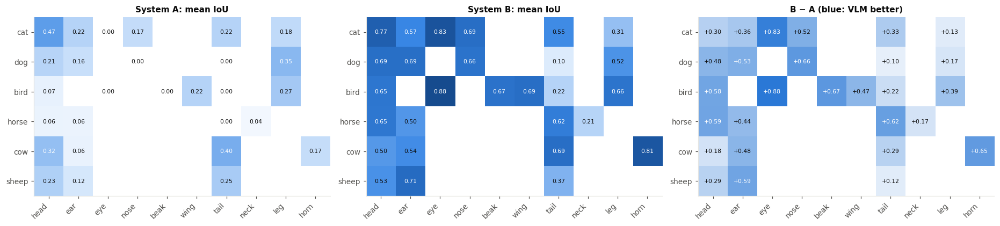

saved -> outputs/figures/metrics.png


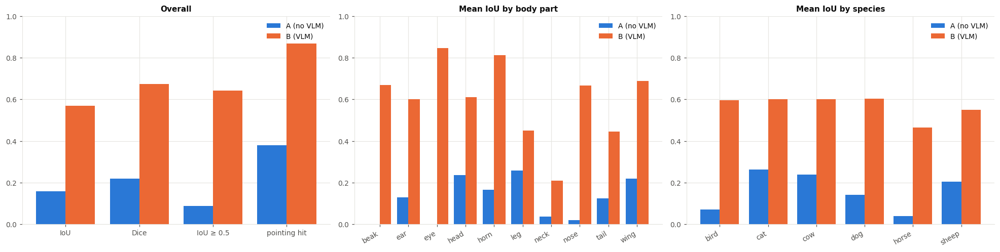

In [24]:
PART_ORDER = [p for p in PART_MAP if p in set(PINFO.part)]
def iou_matrix(sname):
    t = df[df.system == sname].pivot_table(index="cls", columns="part", values="iou", aggfunc="mean")
    return t.reindex(index=[c for c in CFG.classes if c in t.index]).reindex(columns=PART_ORDER)
MA, MB = iou_matrix(A_), iou_matrix(B_)
fig, axes = plt.subplots(1, 3, figsize=(17, 3.9))
heatmap(axes[0], MA.values, MA.index, MA.columns, "System A: mean IoU", vmin=0, vmax=1)
heatmap(axes[1], MB.values, MB.index, MB.columns, "System B: mean IoU", vmin=0, vmax=1)
lim = max(0.05, np.nanmax(np.abs((MB - MA).values)))
heatmap(axes[2], (MB - MA).values, MA.index, MA.columns, "B − A (blue: VLM better)", fmt="{:+.2f}", vmin=-lim, vmax=lim, cmap=DIV)
plt.tight_layout(); savefig(fig, "06_heatmaps.png"); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
ov = df.groupby("system")[["iou", "dice", "iou50", "hit"]].mean().T; ov.index = ["IoU", "Dice", "IoU ≥ 0.5", "pointing hit"]
grouped_bar(ax[0], ov, "Overall")
grouped_bar(ax[1], df.pivot_table(index="part", columns="system", values="iou"), "Mean IoU by body part", rot=30)
grouped_bar(ax[2], df.pivot_table(index="cls", columns="system", values="iou"), "Mean IoU by species", rot=30)
plt.tight_layout(); savefig(fig, "metrics.png"); plt.show()

## 8.4 Prompt following and failure analysis

* **Table**: how often each system understood the prompt (part parsed, species recognised), produced a mask, and
  put it in the right region.
* **Left plot**: empirical CDF of IoU. A curve that is *lower and to the right* is better; the vertical line marks IoU = 0.5.
* **Right plot**: the outcome of every prompt (§7.1). The gap between *right region, imprecise mask* and *wrong region*
  tells whether a system's errors come from the **boundary** (SAM / annotation noise) or from the **prompt**
  (where it looked).

,part parsed (%),species ok (%),mask produced (%),pointing hit (%),IoU ≥ 0.5 (%)
system,,,,,
A (no VLM),100.0,97.1,100.0,38.0,8.8
B (VLM),100.0,83.2,100.0,86.9,64.2


Pointing-game hit rate (%) by part


system,A (no VLM),B (VLM)
part,,
beak,0.0,100.0
ear,33.3,96.3
eye,0.0,100.0
head,46.8,87.2
horn,60.0,100.0
leg,81.8,90.9
neck,25.0,50.0
nose,12.5,100.0
tail,21.1,68.4


saved -> outputs/figures/07_prompt_following.png


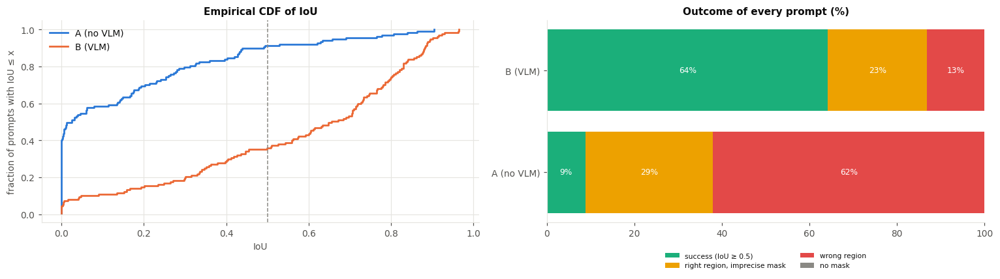

In [25]:
pf = df.groupby("system")[["parse_ok", "species_ok", "found", "hit", "iou50"]].mean().mul(100).round(1)
pf.columns = ["part parsed (%)", "species ok (%)", "mask produced (%)", "pointing hit (%)", "IoU ≥ 0.5 (%)"]
display(pf.rename(index=SYS_NAMES))
hit_part = df.pivot_table(index="part", columns="system", values="hit").mul(100).round(1).rename(columns=SYS_NAMES)
print("Pointing-game hit rate (%) by part"); display(hit_part)

OUTC = df.groupby(["system", "outcome"]).size().unstack(fill_value=0).reindex(columns=OUTCOMES, fill_value=0)
OUTC_PCT = OUTC.div(OUTC.sum(1), axis=0) * 100
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for sname in (A_, B_):
    x = np.sort(W[sname].values); ax[0].step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=SYS_COLOR[sname], label=SYS_NAMES[sname])
ax[0].axvline(0.5, color=INK3, ls="--", lw=1); ax[0].set_xlabel("IoU"); ax[0].set_ylabel("fraction of prompts with IoU ≤ x"); ax[0].set_title("Empirical CDF of IoU"); ax[0].legend()
left = np.zeros(2); oc = [PALETTE[2], PALETTE[3], PALETTE[7], INK3]
for k, o in enumerate(OUTCOMES):
    v = np.array([OUTC_PCT.loc[s_, o] if s_ in OUTC_PCT.index else 0 for s_ in (A_, B_)])
    ax[1].barh([SYS_NAMES[A_], SYS_NAMES[B_]], v, left=left, color=oc[k], label=o)
    for j, val in enumerate(v):
        if val > 6: ax[1].text(left[j] + val / 2, j, f"{val:.0f}%", ha="center", va="center", color="white", fontsize=8)
    left += v
ax[1].set_xlim(0, 100); ax[1].set_title("Outcome of every prompt (%)"); ax[1].legend(ncol=2, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.12)); ax[1].grid(False)
plt.tight_layout(); savefig(fig, "07_prompt_following.png"); plt.show()

## 8.5 Qualitative results

Three views of the same prompts: a **random** selection (`qualitative.png`, used in the report), the prompts where
**B beats A the most**, and where **A beats B the most**. Each row shows the ground truth (green), System A, and
System B (red mask, green boxes = the boxes passed to SAM 2, with the per-prompt IoU).

saved -> outputs/figures/qualitative.png


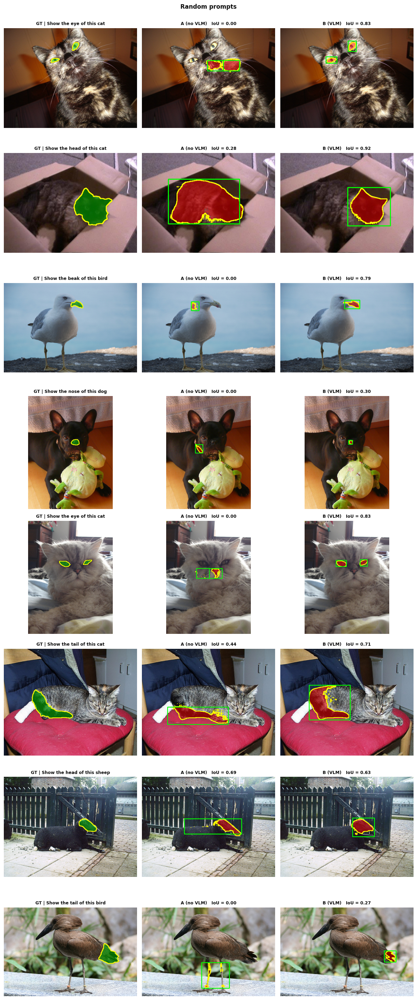

saved -> outputs/figures/08_cases_B_better.png


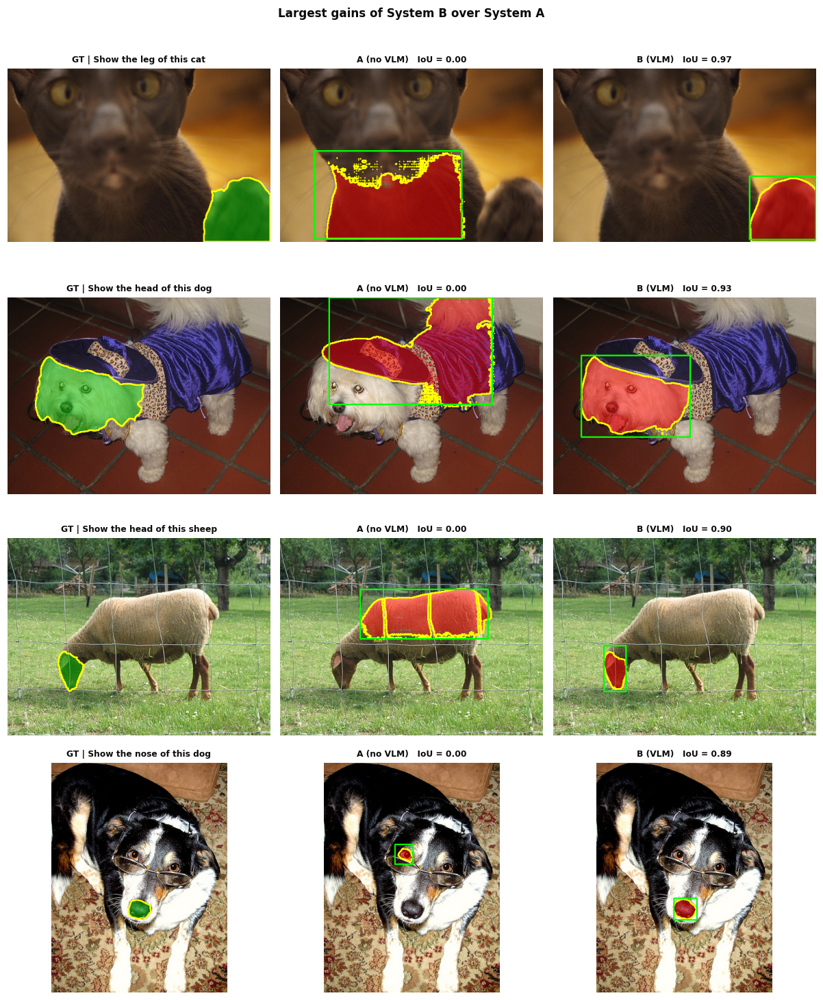

saved -> outputs/figures/09_cases_A_better.png


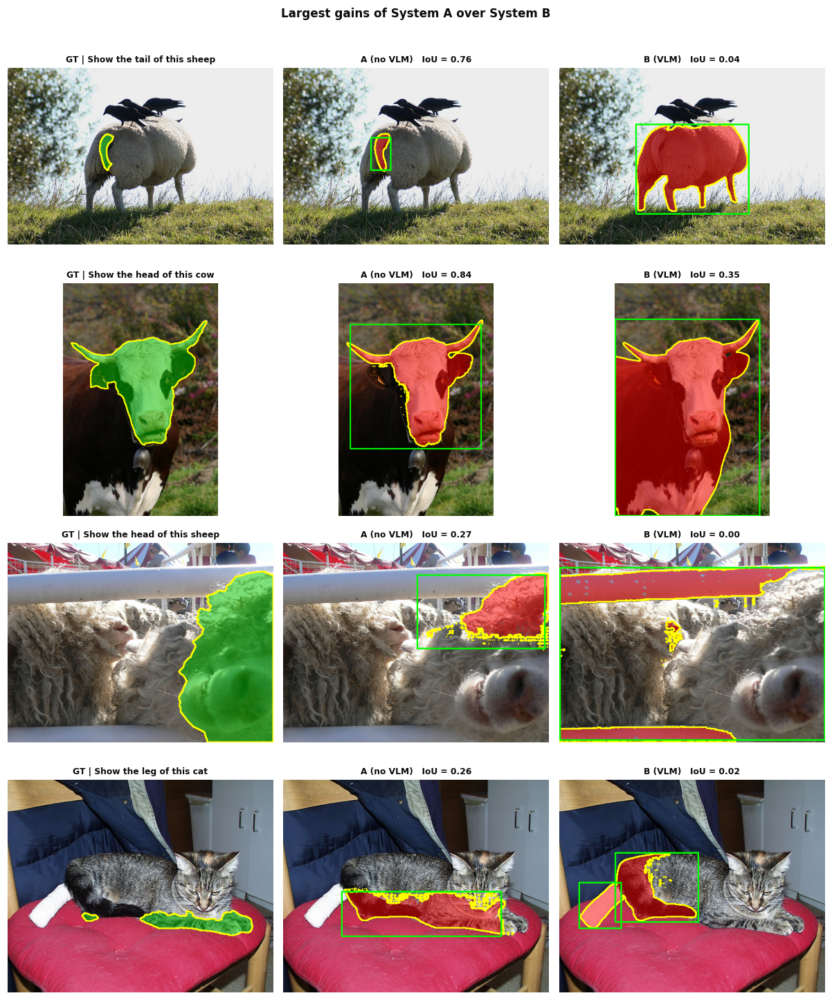

saved -> outputs/figures/10_cases_both_fail.png


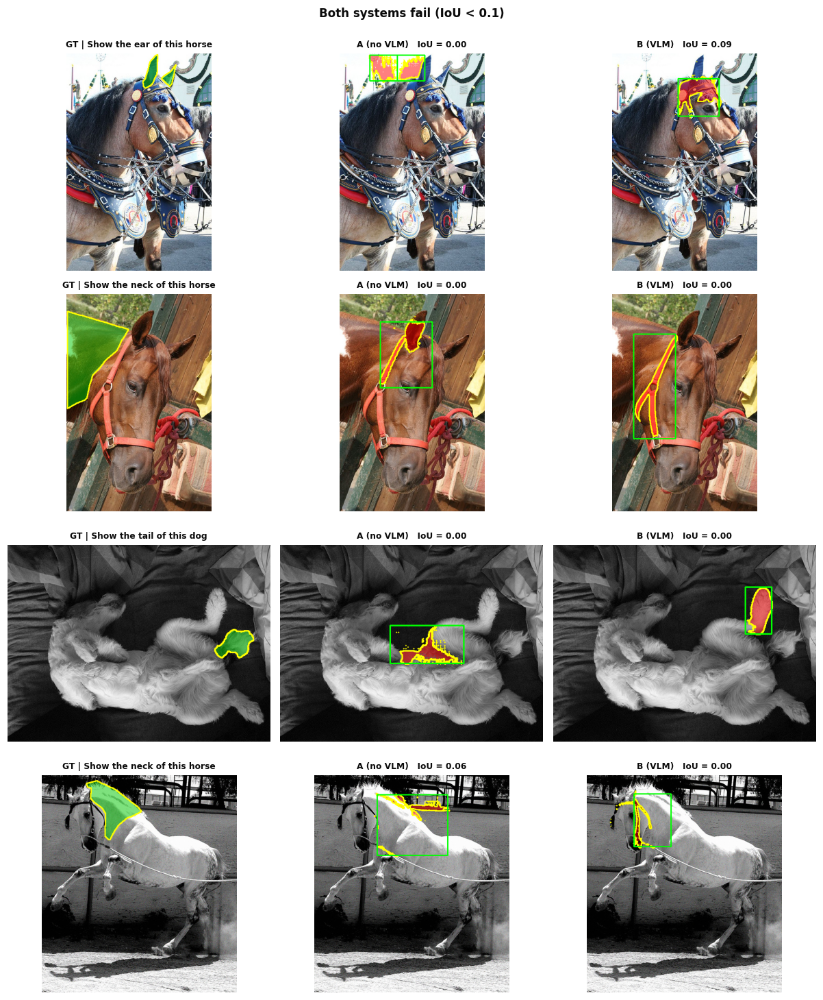

In [26]:
def load_mask(name, i):
    p = MASKS / name / f"{i:03d}.png"
    return (np.array(Image.open(p)) > 127) if p.exists() else None

def get_boxes(name, i):
    r = df[(df.idx == i) & (df.system == name)].iloc[0]
    try: return json.loads(r.boxes)
    except Exception: return []

def show_cases(idxs, title, fname):
    idxs = list(idxs)
    if not idxs: print("no cases for:", title); return
    fig, axs = plt.subplots(len(idxs), 3, figsize=(11, 3.3 * len(idxs))); axs = np.atleast_2d(axs)
    for r_, i in enumerate(idxs):
        s = EVAL_SAMPLES[i]; img = Image.open(s["image_path"]).convert("RGB")
        axs[r_, 0].imshow(overlay(img, s["gt"], color=(0, 200, 0))); axs[r_, 0].set_title(f"GT | {s['prompt']}", fontsize=8)
        for j, name in enumerate((A_, B_), 1):
            iou = float(df[(df.idx == i) & (df.system == name)].iou.values[0])
            axs[r_, j].imshow(overlay(img, load_mask(name, i), get_boxes(name, i))); axs[r_, j].set_title(f"{SYS_NAMES[name]}   IoU = {iou:.2f}", fontsize=8)
        for a in axs[r_]: a.axis("off")
    fig.suptitle(title, y=1.0, fontsize=11, fontweight="bold"); plt.tight_layout(); savefig(fig, fname); plt.show()

rnd = np.random.default_rng(CFG.seed).choice(W.index.values, size=min(8, len(W)), replace=False)
show_cases(sorted(rnd), "Random prompts", "qualitative.png")
dW = (W[B_] - W[A_]).sort_values()
show_cases(dW.index[-4:][::-1], "Largest gains of System B over System A", "08_cases_B_better.png")
show_cases(dW.index[:4], "Largest gains of System A over System B", "09_cases_A_better.png")
both_fail = W[(W[A_] < 0.1) & (W[B_] < 0.1)].index[:4]
show_cases(both_fail, "Both systems fail (IoU < 0.1)", "10_cases_both_fail.png")

## 8.6 The isolated body parts

The deliverable of the task: the **cut-out** each system returns for the same prompt (transparent background shown
white here). The individual PNG files are in `outputs/cutouts/<system>/`.

saved -> outputs/figures/cutout_grid.png


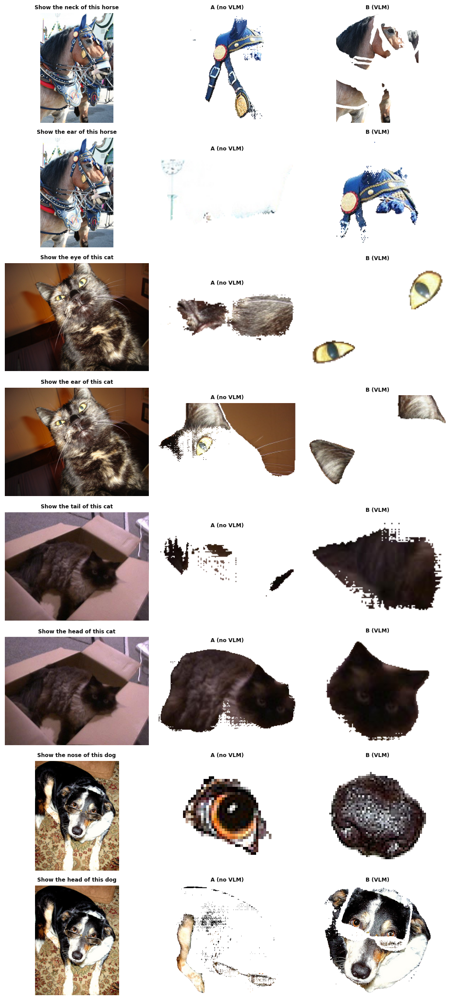

In [33]:
n = min(8, len(EVAL_SAMPLES)); fig, axs = plt.subplots(n, 3, figsize=(9.5, 2.6 * n))
for i in range(n):
    s = EVAL_SAMPLES[i]; axs[i, 0].imshow(Image.open(s["image_path"]).convert("RGB")); axs[i, 0].set_title(s["prompt"], fontsize=8)
    for j, nm in enumerate(SYSTEMS, 1):
        p_ = CUTS / nm / f"{i:03d}_{s['cls']}_{s['part']}.png"
        if p_.exists():
            c = Image.open(p_); bg = Image.new("RGB", c.size, "white"); bg.paste(c, mask=c.split()[3]); axs[i, j].imshow(bg)
        else: axs[i, j].text(0.5, 0.5, "no mask", ha="center", va="center", transform=axs[i, j].transAxes, color=INK3)
        axs[i, j].set_title(SYS_NAMES[nm], fontsize=8)
    for a in axs[i]: a.axis("off")
plt.tight_layout(); savefig(fig, "cutout_grid.png"); plt.show()

## 8.7 Description quality

* **Examples**: the descriptions both systems gave for the same prompts.
* **Metrics** (§7.1): CLIP score (text fits the image crop), species / colour mentions, length, and the share of
  *distinct* texts. System A's *reference similarity* is circular and is shown only for completeness.
* `human_rating_template.csv` contains 30 random outputs to rate on three 1–5 scales (appearance accuracy, functional
  correctness, context awareness).

In [28]:
pd.set_option("display.max_colwidth", 320)
ex = []
for i in sorted(df.idx.unique())[:6]:
    a = df[(df.idx == i) & (df.system == A_)].iloc[0]; b = df[(df.idx == i) & (df.system == B_)].iloc[0]
    ex.append({"prompt": a.prompt, "System A (knowledge base)": a.description or a.error, "System B (VLM)": b.description or b.error})
display(pd.DataFrame(ex))

dd = df[df.found == 1]
DESC = dd.groupby("system").agg(clip=("clip", "mean"), species_mention=("species_mention", "mean"), color_mention=("color_mention", "mean"),
                                n_words=("n_words", "mean"), sim_ref_circular=("sim_ref", "mean"),
                                unique_ratio=("description", lambda s: s.nunique() / max(len(s), 1)))
DESC[["species_mention", "color_mention", "unique_ratio"]] *= 100
display(DESC.round(2).rename(index=SYS_NAMES))

hr = df.sample(min(30, len(df)), random_state=CFG.seed)[["idx", "system", "prompt", "description"]].assign(appearance_1to5="", function_1to5="", context_aware_1to5="")
hr.to_csv(RES / "human_rating_template.csv", index=False)

,prompt,System A (knowledge base),System B (VLM)
0,Show the neck of this horse,"Appearance: The neck is the narrow, muscular region connecting the head to the body. Function: It supports and moves the head, and carries the spinal cord, windpipe, food pipe and blood vessels.","The horse's neck is covered with a blue and white bridle adorned with various decorative elements such as gold medallions and ribbons. The bridle fits snugly around the horse's head, providing control and guidance during riding. Its primary biological function is to help the rider maintain control over the horse wh..."
1,Show the ear of this horse,"Appearance: Ears are paired, usually upright or drooping flaps on the sides or top of the head, covered in fur or skin. Function: They collect sound and help locate where it comes from; in many mammals they also help with balance and heat loss.","The ear of the horse in the image is small, rounded, and positioned on top of the head. It appears to be covered with short, dense hair that is dark brown or black. The ear has a slight curve and is slightly larger than the eye, which is typical for horses.\n\nThe primary biological function of a horse's ear is to ..."
2,Show the eye of this cat,"Appearance: Eyes are small, rounded, paired organs set in the face, with a coloured iris and a dark pupil. Function: They detect light and form images, letting the animal find food, spot predators and navigate.","The eye in the image is large, with a round shape and a black pupil surrounded by a bright yellow iris. The texture appears smooth, and the overall coloration is a mix of black and yellow. This eye belongs to a cat, which has evolved to see well in low light conditions. Cats' eyes have a specialized structure that ..."
3,Show the ear of this cat,"Appearance: Cat ears are triangular, upright and mobile, lined with soft fur. Function: They swivel independently to pinpoint faint sounds such as prey and indicate mood.","The ear in the image is dark gray with a slightly rounded shape and a small opening at the top. It has a smooth texture and appears to be well-groomed. The main biological function of a cat's ear is to help them hear, balance, and communicate through vocalizations."
4,Show the tail of this cat,"Appearance: A cat's tail is long, flexible and furry. Function: It helps balance during jumps and signals mood.","The tail in the image appears to be dark-colored with a slightly fluffy texture, tapering off into a pointed tip. It is relatively small compared to the rest of the body, which is typical for cats. The main biological function of a cat's tail is to provide balance and control during movement, helping them navigate ..."
5,Show the head of this cat,"Appearance: The head is the front end of the body, carrying the eyes, ears, nose and mouth, with a shape and covering that differ by species. Function: It houses the brain and the main sense organs and the mouth for feeding, so it guides perception, feeding and communication.","The cat's head in the image is small relative to its body, with a round face and large, expressive eyes that are dark brown or black. The fur appears soft and fluffy, with a mix of light and dark shades, possibly indicating a Siamese or Burmese breed. Its ears are pointed and upright, which is typical for cats, all..."


,clip,species_mention,color_mention,n_words,sim_ref_circular,unique_ratio
system,,,,,,
A (no VLM),23.59,30.66,43.07,38.15,0.97,12.41
B (VLM),31.39,91.24,99.27,74.38,0.59,100.00


## 8.8 Computational requirements

Wall-clock time per prompt (split into the segmentation stage and the description stage), extra GPU memory during a
call, and parameter count. Memory *for the weights themselves* is in the model table of §3.3.

,A (no VLM),B (VLM)
parameters (M),292.68,3979.07
time / prompt (s),1.09,20.98
segmentation stage (s),1.09,11.38
description stage (s),0.00,9.59
extra GPU memory (MB),1262.03,1262.03
throughput (prompts/min),54.97,2.86


saved -> outputs/figures/11_compute.png


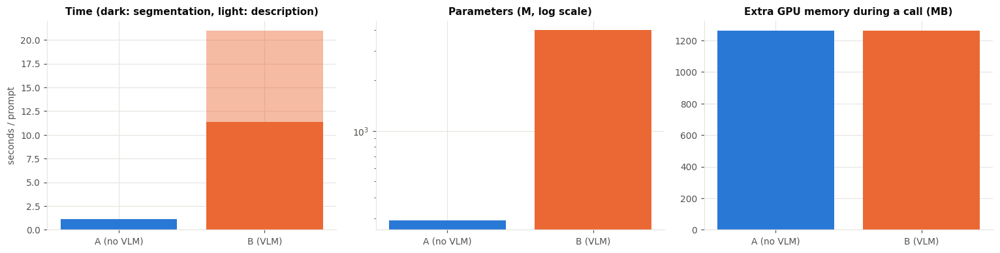

In [39]:
COST = pd.DataFrame({
    "parameters (M)":            {A_: PARAMS[A_], B_: PARAMS[B_]},
    "time / prompt (s)":         {s_: S.loc[s_, "time_s"] for s_ in (A_, B_)},
    "  segmentation stage (s)":  {s_: S.loc[s_, "t_seg"] for s_ in (A_, B_)},
    "  description stage (s)":   {s_: S.loc[s_, "t_desc"] for s_ in (A_, B_)},
    "extra GPU memory (MB)":     {s_: S.loc[s_, "peak_mb"] for s_ in (A_, B_)},
    "throughput (prompts/min)":  {s_: 60 / S.loc[s_, "time_s"] for s_ in (A_, B_)},
}).T.round(2)
display(COST.rename(columns=SYS_NAMES))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for k, s_ in enumerate((A_, B_)):
    ax[0].bar(k, S.loc[s_, "t_seg"], color=SYS_COLOR[s_]); ax[0].bar(k, S.loc[s_, "t_desc"], bottom=S.loc[s_, "t_seg"], color=SYS_COLOR[s_], alpha=0.45)
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels([SYS_NAMES[A_], SYS_NAMES[B_]]); ax[0].set_ylabel("seconds / prompt"); ax[0].set_title("Time (dark: segmentation, light: description)")
ax[1].bar([SYS_NAMES[A_], SYS_NAMES[B_]], [PARAMS[A_], PARAMS[B_]], color=[SYS_COLOR[A_], SYS_COLOR[B_]]); ax[1].set_yscale("log"); ax[1].set_title("Parameters (M, log scale)")
ax[2].bar([SYS_NAMES[A_], SYS_NAMES[B_]], [S.loc[A_, "peak_mb"], S.loc[B_, "peak_mb"]], color=[SYS_COLOR[A_], SYS_COLOR[B_]]); ax[2].set_title("Extra GPU memory during a call (MB)")
plt.tight_layout(); savefig(fig, "11_compute.png"); plt.show()

---
# 9. Ablations: where do the errors come from?

Three questions are answered with cheap extra runs (no VLM calls):

| Variant | Question |
|---|---|
| **A with hand-written priors** (`use_learned_priors=False`) | Do the *learned* priors matter, or would a guess do as well? |
| **A without splitting paired parts** (`split_paired=False`) | Does prompting the left and right ear separately help? |
| **SAM 2 + ground-truth box (oracle)** | What is the *ceiling* of the shared segmenter? The GT mask's connected components are turned into boxes (up to four) and passed to SAM 2. Any shortfall below IoU = 1 is due to SAM 2 and to the coarse Pascal-Part annotation, **not** to the prompting stage. |

The gap between a system and the oracle is therefore the **localisation error** (finding the part), and the gap between
the oracle and 1.0 is the **boundary error** shared by both systems.

  0%|          | 0/137 [00:00<?, ?it/s]

  0%|          | 0/137 [00:00<?, ?it/s]

  0%|          | 0/137 [00:00<?, ?it/s]

,mean IoU,ci_low,ci_high,IoU ≥ 0.5 (%)
variant,,,,
A (full),0.159,0.122,0.199,8.759
"A, hand-written priors",0.168,0.127,0.214,16.058
"A, paired parts not split",0.163,0.125,0.204,9.489
B (VLM),0.569,0.523,0.618,64.234
SAM 2 + GT box (oracle),0.805,0.781,0.826,97.080


saved -> outputs/figures/12_ablations.png


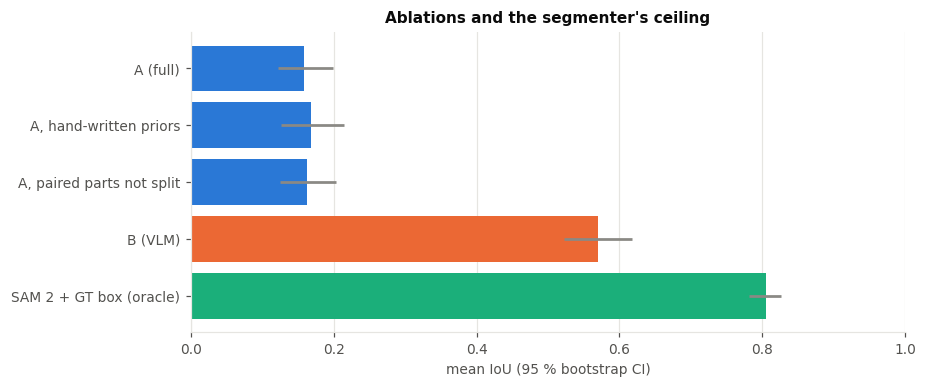

In [30]:
def oracle_mask(img, gt):
    n, lab, stats, _ = cv2.connectedComponentsWithStats(gt.astype(np.uint8), connectivity=8)
    comps = [k for k in range(1, n) if stats[k, cv2.CC_STAT_AREA] >= max(30, 0.05 * gt.sum())]
    comps = sorted(comps, key=lambda k: -stats[k, cv2.CC_STAT_AREA])[:4]
    SAM.set_image(np.array(img)); full = np.zeros(gt.shape, bool)
    for k in comps:
        x, y, w, h = stats[k, :4]; m, _ = SAM.segment([x, y, x + w, y + h]); full |= m[0]
    return full

def iou_over(fn):
    out = []
    for i, s in enumerate(tqdm(EVAL_SAMPLES, leave=False)):
        img = Image.open(s["image_path"]).convert("RGB")
        try: m = fn(img, s)
        except Exception: m = None
        out.append(iou_dice(m, s["gt"])[0] if m is not None and m.any() else 0.0)
    return np.array(out)

A_hand  = SystemA(SAM, YOLO_MODEL, PRIORS, use_learned_priors=False)
A_nosp  = SystemA(SAM, YOLO_MODEL, PRIORS, split_paired=False)
ABL = {"A (full)": W.sort_index()[A_].values,
       "A, hand-written priors": iou_over(lambda img, s: A_hand.run(img, s["prompt"]).get("mask")),
       "A, paired parts not split": iou_over(lambda img, s: A_nosp.run(img, s["prompt"]).get("mask")),
       "B (VLM)": W.sort_index()[B_].values,
       "SAM 2 + GT box (oracle)": iou_over(lambda img, s: oracle_mask(img, s["gt"]))}
ABL_DF = pd.DataFrame([{"variant": k, "mean IoU": v.mean(), "ci_low": boot_ci(v)[0], "ci_high": boot_ci(v)[1], "IoU ≥ 0.5 (%)": 100 * (v >= 0.5).mean()} for k, v in ABL.items()]).set_index("variant")
ABL_DF.round(3).to_csv(RES / "ablation.csv"); display(ABL_DF.round(3))

fig, ax = plt.subplots(figsize=(8.5, 3.6)); cols = [PALETTE[0], PALETTE[0], PALETTE[0], PALETTE[1], PALETTE[2]]
ax.barh(ABL_DF.index[::-1], ABL_DF["mean IoU"][::-1], color=cols[::-1], xerr=[(ABL_DF["mean IoU"] - ABL_DF["ci_low"])[::-1], (ABL_DF["ci_high"] - ABL_DF["mean IoU"])[::-1]], ecolor=INK3)
ax.set_xlim(0, 1); ax.set_xlabel("mean IoU (95 % bootstrap CI)"); ax.set_title("Ablations and the segmenter's ceiling"); ax.grid(axis="y", visible=False)
plt.tight_layout(); savefig(fig, "12_ablations.png"); plt.show()

In [38]:
def pct(x): return f"{100 * x:.1f} %"
sA, sB = S.loc[A_], S.loc[B_]
orc = ABL_DF.loc["SAM 2 + GT box (oracle)", "mean IoU"]
sig = "statistically significant" if (P_ALL == P_ALL and P_ALL < 0.05) else "not statistically significant"
best_B = BY_PART["ΔIoU (B−A)"].idxmax(); worst_B = BY_PART["ΔIoU (B−A)"].idxmin()
share_loc = (orc - max(sA["iou"], sB["iou"])) / max(1 - max(sA["iou"], sB["iou"]), 1e-9)

table = f"""
| | System A (no VLM) | System B (VLM) | SAM 2 + GT box (ceiling) |
|---|---|---|---|
| mean IoU ↑ | {sA['iou']:.3f} | {sB['iou']:.3f} | {orc:.3f} |
| mean Dice ↑ | {sA['dice']:.3f} | {sB['dice']:.3f} | – |
| IoU ≥ 0.5 | {pct(sA['iou50'])} | {pct(sB['iou50'])} | {pct(ABL_DF.loc['SAM 2 + GT box (oracle)', 'IoU ≥ 0.5 (%)'] / 100)} |
| pointing-game hit | {pct(sA['hit'])} | {pct(sB['hit'])} | – |
| part parsed correctly | {pct(sA['parse_ok'])} | {pct(sB['parse_ok'])} | – |
| species recognised | {pct(sA['species_ok'])} | {pct(sB['species_ok'])} | – |
| mask produced | {pct(sA['found'])} | {pct(sB['found'])} | – |
| CLIP score (text–crop) ↑ | {sA['clip']:.2f} | {sB['clip']:.2f} | – |
| description names species / colour | {pct(DESC.loc[A_, 'species_mention'] / 100)} / {pct(DESC.loc[A_, 'color_mention'] / 100)} | {pct(DESC.loc[B_, 'species_mention'] / 100)} / {pct(DESC.loc[B_, 'color_mention'] / 100)} | – |
| distinct descriptions | {DESC.loc[A_, 'unique_ratio']:.0f} % | {DESC.loc[B_, 'unique_ratio']:.0f} % | – |
| time per prompt | {sA['time_s']:.2f} s | {sB['time_s']:.2f} s | – |
| parameters | {PARAMS[A_]:,.0f} M | {PARAMS[B_]:,.0f} M | – |
"""
bullets = f"""
**What the numbers say** (n = {len(W)} prompts on {len({s_['id'] for s_ in EVAL_SAMPLES})} held-out images).

1. **Segmentation.** System B reaches mean IoU {sB['iou']:.3f} against {sA['iou']:.3f} for System A (ΔIoU = {sB['iou'] - sA['iou']:+.3f}; paired Wilcoxon p = {P_ALL:.3g}, {sig}). B is better on {(d_all > 0.01).sum()} prompts, A on {(d_all < -0.01).sum()}, {(d_all.abs() <= 0.01).sum()} are ties.
2. **Prompt following.** The correct part is named in {pct(sA['parse_ok'])} (A) vs {pct(sB['parse_ok'])} (B) of prompts, and the mask centroid lands inside the true part in {pct(sA['hit'])} vs {pct(sB['hit'])}. A mask is produced for {pct(sA['found'])} vs {pct(sB['found'])}.
3. **Where each system wins.** The largest gain of B over A is on **{best_B}** (ΔIoU = {BY_PART.loc[best_B, 'ΔIoU (B−A)']:+.3f}); the smallest, or the only gain of A, is on **{worst_B}** ({BY_PART.loc[worst_B, 'ΔIoU (B−A)']:+.3f}).
4. **Error structure.** For System A, {OUTC_PCT.loc[A_, 'wrong region']:.0f} % of prompts end in the *wrong region* and {OUTC_PCT.loc[A_, 'right region, imprecise mask']:.0f} % in the right region with a poor mask; for System B the figures are {OUTC_PCT.loc[B_, 'wrong region']:.0f} % and {OUTC_PCT.loc[B_, 'right region, imprecise mask']:.0f} %.
5. **Ceiling of the shared segmenter.** SAM 2 prompted with the *true* box reaches IoU {orc:.3f}. The remaining {1 - orc:.3f} is boundary error common to both systems (coarse annotations, thin structures). Relative to the best system, about {100 * share_loc:.0f} % of the remaining headroom is **localisation** error, i.e. choosing the prompt.
6. **Learned priors.** Replacing them by hand-written boxes changes System A's IoU from {ABL_DF.loc['A (full)', 'mean IoU']:.3f} to {ABL_DF.loc['A, hand-written priors', 'mean IoU']:.3f}; not splitting paired parts gives {ABL_DF.loc['A, paired parts not split', 'mean IoU']:.3f}.
7. **Descriptions.** The VLM text fits the cropped part with a CLIP score of {sB['clip']:.2f} (A: {sA['clip']:.2f}) and is distinct in {DESC.loc[B_, 'unique_ratio']:.0f} % of cases (A: {DESC.loc[A_, 'unique_ratio']:.0f} %); it names a colour in {DESC.loc[B_, 'color_mention']:.0f} % of descriptions (A: {DESC.loc[A_, 'color_mention']:.0f} %). Factual correctness should be judged with the human-rating template.
8. **Cost.** System B needs {PARAMS[B_] / PARAMS[A_]:.0f}× the parameters and {sB['time_s'] / max(sA['time_s'], 1e-9):.1f}× the time per prompt ({sB['time_s']:.2f} s vs {sA['time_s']:.2f} s).
"""
display(Markdown(table)); display(Markdown(bullets))
open(RES / "results_at_a_glance.md", "w").write(table + "\n" + bullets)


| | System A (no VLM) | System B (VLM) | SAM 2 + GT box (ceiling) |
|---|---|---|---|
| mean IoU ↑ | 0.159 | 0.569 | 0.805 |
| mean Dice ↑ | 0.221 | 0.674 | – |
| IoU ≥ 0.5 | 8.8 % | 64.2 % | 97.1 % |
| pointing-game hit | 38.0 % | 86.9 % | – |
| part parsed correctly | 100.0 % | 100.0 % | – |
| species recognised | 97.1 % | 83.2 % | – |
| mask produced | 100.0 % | 100.0 % | – |
| CLIP score (text–crop) ↑ | 23.59 | 31.39 | – |
| description names species / colour | 30.7 % / 43.1 % | 91.2 % / 99.3 % | – |
| distinct descriptions | 12 % | 100 % | – |
| time per prompt | 1.09 s | 20.98 s | – |
| parameters | 293 M | 3,979 M | – |



**What the numbers say** (n = 137 prompts on 72 held-out images).

1. **Segmentation.** System B reaches mean IoU 0.569 against 0.159 for System A (ΔIoU = +0.410; paired Wilcoxon p = 8.01e-20, statistically significant). B is better on 116 prompts, A on 13, 8 are ties.
2. **Prompt following.** The correct part is named in 100.0 % (A) vs 100.0 % (B) of prompts, and the mask centroid lands inside the true part in 38.0 % vs 86.9 %. A mask is produced for 100.0 % vs 100.0 %.
3. **Where each system wins.** The largest gain of B over A is on **eye** (ΔIoU = +0.846); the smallest, or the only gain of A, is on **neck** (+0.173).
4. **Error structure.** For System A, 62 % of prompts end in the *wrong region* and 29 % in the right region with a poor mask; for System B the figures are 13 % and 23 %.
5. **Ceiling of the shared segmenter.** SAM 2 prompted with the *true* box reaches IoU 0.805. The remaining 0.195 is boundary error common to both systems (coarse annotations, thin structures). Relative to the best system, about 55 % of the remaining headroom is **localisation** error, i.e. choosing the prompt.
6. **Learned priors.** Replacing them by hand-written boxes changes System A's IoU from 0.159 to 0.168; not splitting paired parts gives 0.163.
7. **Descriptions.** The VLM text fits the cropped part with a CLIP score of 31.39 (A: 23.59) and is distinct in 100 % of cases (A: 12 %); it names a colour in 99 % of descriptions (A: 43 %). Factual correctness should be judged with the human-rating template.
8. **Cost.** System B needs 14× the parameters and 19.2× the time per prompt (20.98 s vs 1.09 s).


2254